# [GSE288128](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE166142)

> - Author: Cao Qiang
> - Email: qiangcao2014@gmail.com
> - Created: 2025-08-27
> - Modified: 2025-08-27

# 1. Experimental Design

> Recruitment to the nuclear periphery enhances repression of H3K9me2-marked genes and transposons to shape cell fate.
> - Marin, H.C., Allen, C., Simental, E. et al. The nuclear periphery confers repression on H3K9me2-marked genes and transposons to shape cell fate. Nat Cell Biol 27, 1311–1326 (2025). https://doi.org/10.1038/s41556-025-01703-z.
> - fr_firststrand total RNA-seq
> - Illumina Stranded Total RNA Prep with Ribo-Zero Plus kit (Illumina, 20040525)
> - Illumina NextSeq 2000, PE150
> - mm10

| Cell | Organism | Source | Genotype | Replicate |
| - | - | - | - | - |
| mESC | Mus musculus | Embryionic stem cells | WT | rep1~8 |
| EpiLC | Mus musculus | Epiblast like cells | WT | rep1~8 |

# 2. Preprocessing

In [1]:
library(tidyverse)
suppressPackageStartupMessages(library(limma))
suppressPackageStartupMessages(library(edgeR))
suppressPackageStartupMessages(library(DESeq2))
suppressPackageStartupMessages(library(ggrepel))
suppressPackageStartupMessages(library(pheatmap))
suppressPackageStartupMessages(library(patchwork))
suppressPackageStartupMessages(library(RColorBrewer))

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


## 1). Import Data

In [2]:
data_dir <- "~/dataset_1/bulk_omics/cutrun_Mm_mESC_Lamin_GSE288128/04_output_rnaseq"

### a). FeatureCounts

In [3]:
raw_counts <- file.path(data_dir, "04_counts", "featureCounts_Wildtype.tsv") |>
    read.table(header = TRUE, sep = "\t", check.names = FALSE)

colnames(raw_counts) <- colnames(raw_counts) |> 
    sub("^04_output_rnaseq/03_align/(.*?).Aligned.out.bam", "\\1", x = _)

dim(raw_counts)

[1] 55335    24

In [ ]:
coldata <- colnames(raw_counts) |> 
    tibble(sample = _) |> 
    filter(str_detect(sample, fixed("Wildtype"))) |> 
    separate(
        col = sample, into = c("Cell", "Group", "Replicate"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate(
        sample = sub("_Wildtype_", "_", sample),
        Cell = factor(Cell, levels = c("mESC", "EpiLC")), 
        Replicate = factor(Replicate)) |> 
    arrange(Cell, Replicate) |>
    column_to_rownames("sample")

coldata

,Cell,Group,Replicate
,<fct>,<chr>,<fct>
mESC_rep1,mESC,Wildtype,rep1
mESC_rep2,mESC,Wildtype,rep2
mESC_rep3,mESC,Wildtype,rep3
mESC_rep4,mESC,Wildtype,rep4
mESC_rep5,mESC,Wildtype,rep5
mESC_rep6,mESC,Wildtype,rep6


In [5]:
anno_gene <- raw_counts |> 
    select(
        Geneid, symbol = gene_name, type = gene_type, 
        basepairs = Length) |>
    column_to_rownames(var = "Geneid") |> 
    DataFrame()

In [6]:
raw_counts <- raw_counts |>
    column_to_rownames("Geneid") |>
    select(matches("Wildtype")) |>
    rename_with(~ sub("_Wildtype_", "_", .x)) |>
    select(any_of(rownames(coldata))) |>
    as.matrix()

In [7]:
DESeqDataSetFromMatrix(
    countData = raw_counts, rowData = anno_gene,
    colData = coldata, design = ~ Cell)

class: DESeqDataSet 
dim: 55335 16 
metadata(1): version
assays(1): counts
rownames(55335): ENSMUSG00000102693.1 ENSMUSG00000064842.1 ...
  ENSMUSG00000064371.1 ENSMUSG00000064372.1
rowData names(3): symbol type basepairs
colnames(16): mESC_rep1 mESC_rep2 ... EpiLC_rep7 EpiLC_rep8
colData names(3): Cell Group Replicate

### b). HTseq-count

In [8]:
htseq_files <- file.path(data_dir, "04_counts") |>
    list.files(pattern = ".tsv") |>
    str_subset(pattern = "featureCounts", negate = TRUE) |>
    str_subset(pattern = "Wildtype")

In [9]:
coldata <- tibble(
    sampleName = sub("(.*?).tsv", "\\1", htseq_files),
    fileName = htseq_files) |> 
    separate(
        col = sampleName, into = c("Cell", "Group", "Replicate"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate(
        sampleName = sub("_Wildtype_", "_", sampleName),
        Cell = factor(Cell, levels = c("mESC", "EpiLC")), 
        Replicate = factor(Replicate)) |> 
    arrange(Cell, Replicate) |>
    select("sampleName", "fileName", "Cell", "Group", "Replicate") |>
    as.data.frame()

head(coldata)

,sampleName,fileName,Cell,Group,Replicate
,<chr>,<chr>,<fct>,<chr>,<fct>
1,mESC_rep1,mESC_Wildtype_rep1.tsv,mESC,Wildtype,rep1
2,mESC_rep2,mESC_Wildtype_rep2.tsv,mESC,Wildtype,rep2
3,mESC_rep3,mESC_Wildtype_rep3.tsv,mESC,Wildtype,rep3
4,mESC_rep4,mESC_Wildtype_rep4.tsv,mESC,Wildtype,rep4
5,mESC_rep5,mESC_Wildtype_rep5.tsv,mESC,Wildtype,rep5
6,mESC_rep6,mESC_Wildtype_rep6.tsv,mESC,Wildtype,rep6


In [10]:
DESeqDataSetFromHTSeqCount(
    sampleTable = coldata, design = ~ Cell,
    directory = file.path(data_dir, "04_counts"))

class: DESeqDataSet 
dim: 55335 16 
metadata(1): version
assays(1): counts
rownames(55335): ENSMUSG00000000001.4 ENSMUSG00000000003.15 ...
  ENSMUSG00000118577.1 ENSMUSG00000118578.1
rowData names(0):
colnames(16): mESC_rep1 mESC_rep2 ... EpiLC_rep7 EpiLC_rep8
colData names(3): Cell Group Replicate

### c). Salmon

#### tximport

In [11]:
gtf <- rtracklayer::import(
    "~/reference/Mus_musculus/mm10/gencode.vM23.annotation.gtf")

tx2gene <- gtf |> 
    subset(
        type == "transcript", 
        select = c("transcript_id", "gene_id")) |> 
    mcols()

In [12]:
salmon_dir <- file.path(data_dir, "05_salmon")
salmon_files <- list.dirs(salmon_dir, recursive = FALSE, full.names = FALSE) |>
    str_subset(pattern = "Wildtype")
salmon_quants <- setNames(
    file.path(salmon_dir, salmon_files, "quant.sf"),
    salmon_files)

In [13]:
coldata <- tibble(sample = names(salmon_quants)) |> 
    separate(
        col = sample, into = c("Cell", "Group", "Replicate"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate(
        sample = sub("_Wildtype_", "_", sample),
        Cell = factor(Cell, levels = c("mESC", "EpiLC")), 
        Replicate = factor(Replicate)) |> 
    arrange(Cell, Replicate) |>
    column_to_rownames("sample")

names(salmon_quants) <- sub("_Wildtype_", "_", names(salmon_quants))
salmon_quants <- salmon_quants[rownames(coldata)]

head(coldata)

,Cell,Group,Replicate
,<fct>,<chr>,<fct>
mESC_rep1,mESC,Wildtype,rep1
mESC_rep2,mESC,Wildtype,rep2
mESC_rep3,mESC,Wildtype,rep3
mESC_rep4,mESC,Wildtype,rep4
mESC_rep5,mESC,Wildtype,rep5
mESC_rep6,mESC,Wildtype,rep6


In [14]:
# suppressPackageStartupMessages(library(tximport))
txi <- tximport::tximport(
    salmon_quants, type = "salmon", tx2gene = tx2gene, 
    ignoreAfterBar = TRUE, ignoreTxVersion = FALSE)

reading in files with read_tsv

1 
2 
3 
4 
5 
6 
7 
8 
9 
10 
11 
12 
13 
14 
15 
16 


summarizing abundance

summarizing counts

summarizing length



In [15]:
DESeqDataSetFromTximport(txi, colData = coldata, design = ~ Cell)

using counts and average transcript lengths from tximport



class: DESeqDataSet 
dim: 54281 16 
metadata(1): version
assays(2): counts avgTxLength
rownames(54281): ENSMUSG00000000001.4 ENSMUSG00000000003.15 ...
  ENSMUSG00000118577.1 ENSMUSG00000118578.1
rowData names(0):
colnames(16): mESC_rep1 mESC_rep2 ... EpiLC_rep7 EpiLC_rep8
colData names(3): Cell Group Replicate

#### tximeta

In [16]:
salmon_dirs <- file.path(data_dir, "05_salmon") |>
    list.dirs(recursive = FALSE, full.names = FALSE) |>
    str_subset(pattern = "Wildtype")

In [17]:
coldata <- tibble(
    names = salmon_dirs, 
    files = file.path(data_dir, "05_salmon", salmon_dirs, "quant.sf")) |> 
    separate(
        col = names, into = c("Cell", "Group", "Replicate"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate(
        names = sub("_Wildtype_", "_", names),
        Cell = factor(Cell, levels = c("mESC", "EpiLC")), 
        Replicate = factor(Replicate)) |> 
    arrange(Cell, Replicate) |>
    select("names", "files", "Cell", "Group", "Replicate") |>
    as.data.frame()

coldata |> dplyr::select(-one_of("files")) |> head()

,names,Cell,Group,Replicate
,<chr>,<fct>,<chr>,<fct>
1,mESC_rep1,mESC,Wildtype,rep1
2,mESC_rep2,mESC,Wildtype,rep2
3,mESC_rep3,mESC,Wildtype,rep3
4,mESC_rep4,mESC,Wildtype,rep4
5,mESC_rep5,mESC,Wildtype,rep5
6,mESC_rep6,mESC,Wildtype,rep6


In [18]:
# suppressPackageStartupMessages(library(tximeta))
tximeta::makeLinkedTxome(
    indexDir = "~/reference/Mus_musculus/mm10/index/salmon_index", 
    source = "GENCODE", organism = "Mus musculus", 
    release = "M23", genome = "GRCm38",
    fasta = "~/reference/Mus_musculus/mm10/gencode.vM23.transcripts.fa", 
    gtf = "~/reference/Mus_musculus/mm10/index/genome.gtf", 
    write = FALSE)

reading digest from indexDir: ~/reference/Mus_musculus/mm10/index/salmon_index

NOTE: linkedTxome with source='GENCODE', set useHub=FALSE in tximeta
to avoid download of reference txome from AnnotationHub.
alternatively use a different string for source argument, e.g. LocalGENCODE

saving linkedTxome in bfc (first time)



In [19]:
# There is a network problem
se <- tximeta::tximeta(coldata, useHub = FALSE)
gse <- tximeta::summarizeToGene(se)

importing salmon quantification files

reading in files with read_tsv

1 
2 
3 
4 
5 
6 
7 
8 
9 
10 
11 
12 
13 
14 
15 
16 


found matching linkedTxome:
[ GENCODE - Mus musculus - release M23 ]

building TxDb with 'txdbmaker' package

Import genomic features from the file as a GRanges object ... 
OK

Prepare the 'metadata' data frame ... 
OK

Make the TxDb object ... 
Warning message in .get_cds_IDX(mcols0$type, mcols0$phase):
"The "phase" metadata column contains non-NA values for features of type
  stop_codon. This information was ignored."
Warning message in .makeTxDb_normarg_chrominfo(chrominfo):
"genome version information is not available for this TxDb object"
OK

generating transcript ranges

fetching genome info for GENCODE

loading existing TxDb created: 2026-06-15 13:51:38

Loading required package: GenomicFeatures

Loading required package: AnnotationDbi


Attaching package: 'AnnotationDbi'


The following object is masked from 'package:dplyr':

    select


obtaining tra

In [20]:
DESeqDataSet(gse, design = ~ Cell)

using counts and average transcript lengths from tximeta



class: DESeqDataSet 
dim: 54281 16 
metadata(8): tximetaInfo quantInfo ... assignRanges version
assays(3): counts abundance avgTxLength
rownames(54281): ENSMUSG00000000001.4 ENSMUSG00000000003.15 ...
  ENSMUSG00000118577.1 ENSMUSG00000118578.1
rowData names(2): gene_id tx_ids
colnames(16): mESC_rep1 mESC_rep2 ... EpiLC_rep7 EpiLC_rep8
colData names(4): names Cell Group Replicate

### d). kallisto

#### tximport

In [21]:
kallisto_dir <- file.path(data_dir, "05_kallisto")
kallisto_files <- list.dirs(kallisto_dir, recursive = FALSE, full.names = FALSE) |>
    str_subset(pattern = "Wildtype")
kallisto_quants <- setNames(
    file.path(kallisto_dir, kallisto_files, "abundance.h5"),
    kallisto_files)

In [22]:
coldata <- tibble(sample = names(kallisto_quants)) |> 
    separate(
        col = sample, into = c("Cell", "Group", "Replicate"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate(
        sample = sub("_Wildtype_", "_", sample),
        Cell = factor(Cell, levels = c("mESC", "EpiLC")), 
        Replicate = factor(Replicate)) |> 
    arrange(Cell, Replicate) |>
    column_to_rownames("sample")

names(kallisto_quants) <- sub("_Wildtype_", "_", names(kallisto_quants))
kallisto_quants <- kallisto_quants[rownames(coldata)]

head(coldata)

,Cell,Group,Replicate
,<fct>,<chr>,<fct>
mESC_rep1,mESC,Wildtype,rep1
mESC_rep2,mESC,Wildtype,rep2
mESC_rep3,mESC,Wildtype,rep3
mESC_rep4,mESC,Wildtype,rep4
mESC_rep5,mESC,Wildtype,rep5
mESC_rep6,mESC,Wildtype,rep6


In [23]:
# suppressPackageStartupMessages(library(tximport))
txi <- tximport::tximport(
    kallisto_quants, type = "kallisto", tx2gene = tx2gene, 
    ignoreAfterBar = TRUE, ignoreTxVersion = FALSE)

1 
2 
3 
4 
5 
6 
7 
8 
9 
10 
11 
12 
13 
14 
15 
16 


summarizing abundance

summarizing counts

summarizing length



In [24]:
DESeqDataSetFromTximport(txi, colData = coldata, design = ~ Cell)

using counts and average transcript lengths from tximport



class: DESeqDataSet 
dim: 55335 16 
metadata(1): version
assays(2): counts avgTxLength
rownames(55335): ENSMUSG00000000001.4 ENSMUSG00000000003.15 ...
  ENSMUSG00000118577.1 ENSMUSG00000118578.1
rowData names(0):
colnames(16): mESC_rep1 mESC_rep2 ... EpiLC_rep7 EpiLC_rep8
colData names(3): Cell Group Replicate

## 2). Object Construction

In [25]:
eSet <- SummarizedExperiment(
    assays = list(counts = raw_counts), 
    rowData = anno_gene, colData = coldata)

eSet

class: SummarizedExperiment 
dim: 55335 16 
metadata(0):
assays(1): counts
rownames(55335): ENSMUSG00000102693.1 ENSMUSG00000064842.1 ...
  ENSMUSG00000064371.1 ENSMUSG00000064372.1
rowData names(3): symbol type basepairs
colnames(16): mESC_rep1 mESC_rep2 ... EpiLC_rep7 EpiLC_rep8
colData names(3): Cell Group Replicate

In [26]:
dds <- DESeqDataSetFromMatrix(
    countData = raw_counts, rowData = anno_gene,
    colData = coldata, design = ~ Cell)

dds

class: DESeqDataSet 
dim: 55335 16 
metadata(1): version
assays(1): counts
rownames(55335): ENSMUSG00000102693.1 ENSMUSG00000064842.1 ...
  ENSMUSG00000064371.1 ENSMUSG00000064372.1
rowData names(3): symbol type basepairs
colnames(16): mESC_rep1 mESC_rep2 ... EpiLC_rep7 EpiLC_rep8
colData names(3): Cell Group Replicate

In [27]:
dgel <- DGEList(
    counts = raw_counts, genes = anno_gene, 
    samples = coldata, group = coldata$Cell)

## 3). Low-Count Filtering

> - Filter low expressed genes to reduce the size of the object and increase the speed of the function

In [28]:
keep <- rowSums(assay(eSet) >= 10) >= 8
# keep <- rowSums(counts(dds) >= 10) >= 8

tab <- table(keep)

cat(
    "Filtered genes summary:\n",
    "Pass:", tab["TRUE"], "\n",
    "Remove:", tab["FALSE"], "\n",
    "Retention rate:", round(tab["TRUE"]/sum(tab)*100, 2), "%\n"
)

eSet <- eSet[keep, ]
dds <- dds[keep, ]

Filtered genes summary:
 Pass: 17154 
 Remove: 38181 
 Retention rate: 31 %


In [29]:
keep <- filterByExpr(dgel, group = dgel$samples$group)

tab <- table(keep)

cat(
    "Filtered genes summary:\n",
    "Pass:", tab["TRUE"], "\n",
    "Remove:", tab["FALSE"], "\n",
    "Retention rate:", round(tab["TRUE"]/sum(tab)*100, 2), "%\n"
)

dgel <- dgel[keep, , keep.lib.sizes = FALSE]
# Normalize Library Sizes
dgel <- normLibSizes(dgel)

Filtered genes summary:
 Pass: 16976 
 Remove: 38359 
 Retention rate: 30.68 %


# 3. Normalization

In [30]:
tpm <- assay(eSet) |>
    sweep(1, rowData(eSet)$basepairs, FUN = "/") |>
    (\(rpk) sweep(rpk, 2, colSums(rpk), FUN = "/") * 1e6)()

In [31]:
dds <- estimateSizeFactors(dds)
# Calculation of fpkm expression matrix adjusted by normalization factor using the DESeq2 method.
norm_fpkm <- fpkm(dds, robust = TRUE)

In [32]:
# Calculation of cpm expression matrix adjusted by normalization factor using the TMM method.
norm_cpm <- cpm(dgel, normalized.lib.sizes = TRUE, log = FALSE)

In [33]:
design <- model.matrix(~ group, data = dgel$samples)
norm_v <- voom(dgel, design, plot = FALSE)

In [34]:
rld <- rlog(dds, blind = FALSE)

In [35]:
suppressPackageStartupMessages(library(vsn))

In [36]:
common_theme <- theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [37]:
p1 <- meanSdPlot(log2(counts(dds) + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = expression(-log[2](Count+1))) + 
    common_theme
p2 <- meanSdPlot(log2(tpm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = expression(-log[2](TPM+1))) + 
    common_theme
p3 <- meanSdPlot(assay(rld), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "rlog") + 
    common_theme
p4 <- meanSdPlot(log2(norm_fpkm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "DESeq2, FPKM") + 
    common_theme
p5 <- meanSdPlot(log2(norm_cpm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "edgeR's TMM, CPM") + 
    common_theme
p6 <- meanSdPlot(norm_v$E, ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "limma's voom") + 
    common_theme

Warning message:
"`aes_string()` was deprecated in ggplot2 3.0.0.
ℹ Please use tidy evaluation idioms with `aes()`.
ℹ See also `vignette("ggplot2-in-packages")` for more information.
ℹ The deprecated feature was likely used in the vsn package.
  Please report the issue to the authors."


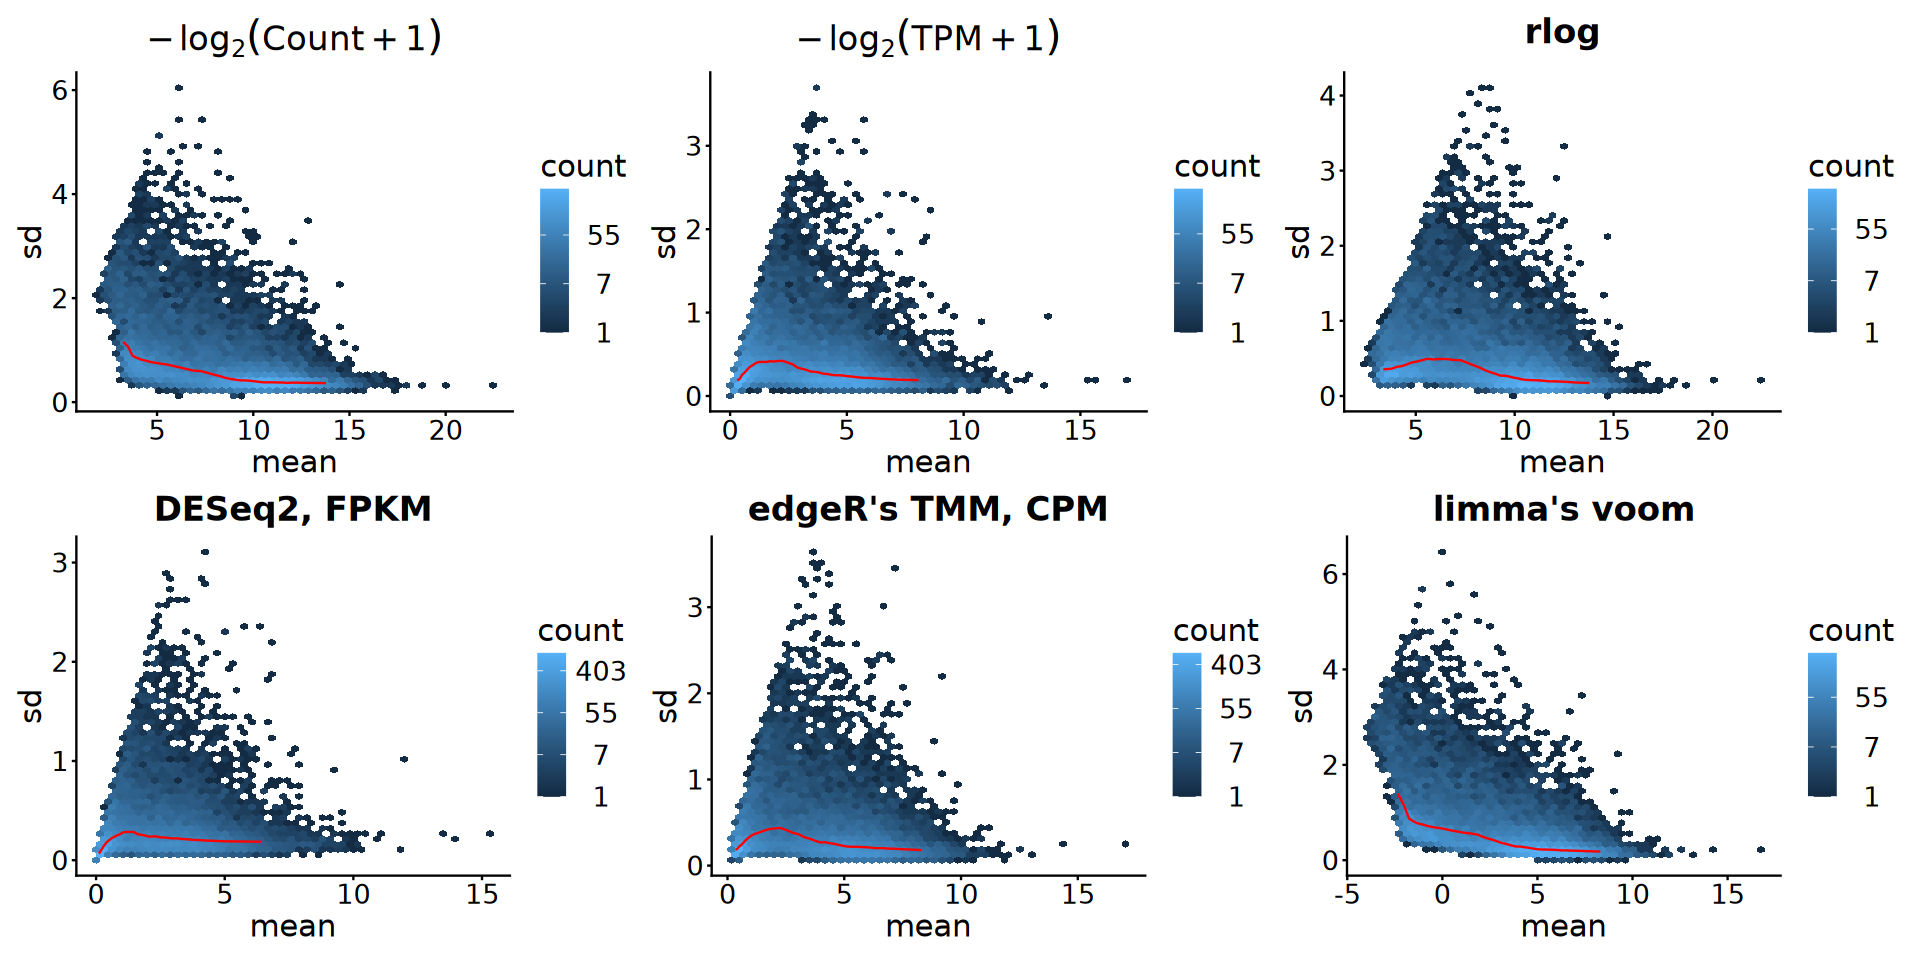

In [38]:
options(repr.plot.width = 16, repr.plot.height = 8)
(p1 + p2 + p3) / (p4 + p5 + p6)

# 4. Exploration

In [39]:
norm_mat <- log2(tpm + 1)
norm_vs <- assay(rld)

### 1). Overview

In [40]:
plot_df <- colData(eSet) |> as.data.frame() |>
    arrange(Cell, Replicate) |> 
    rownames_to_column(var = "Sample") |>
    mutate(librarySize = colSums(assay(eSet))[Sample])

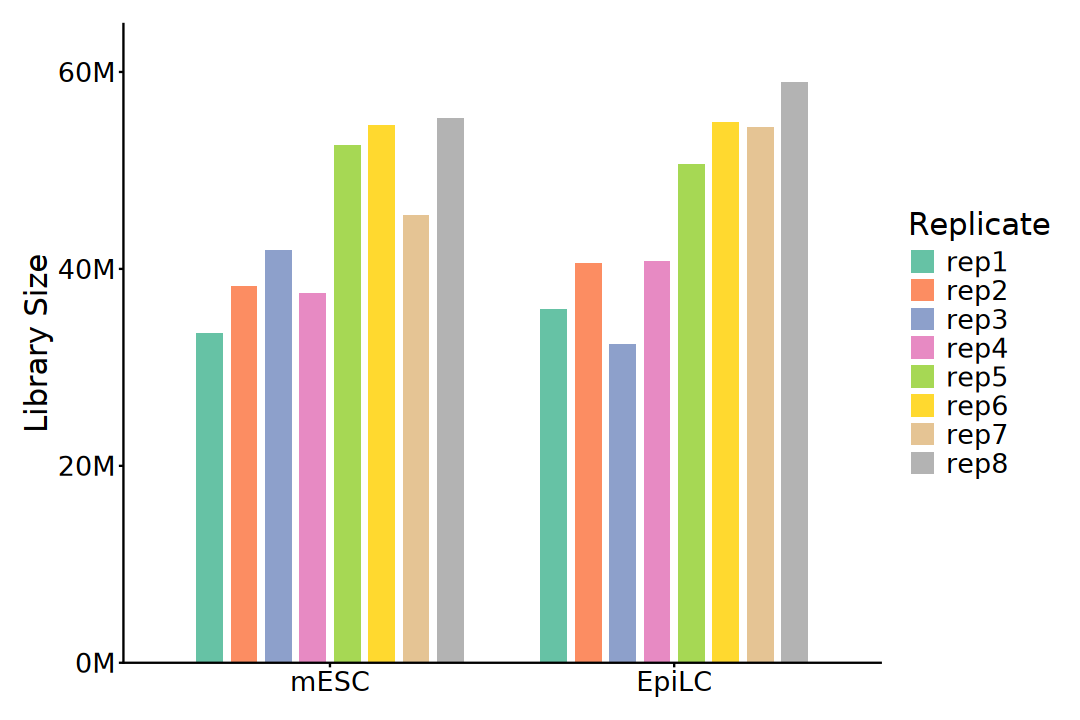

In [41]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(plot_df, aes(x = Cell, y = librarySize, group = Replicate)) +
    geom_bar(
        aes(fill = Replicate), stat = "identity",
        position = position_dodge(width = 0.8),
        width = 0.6, linewidth = 1.5) +
    scale_y_continuous(
        labels = scales::label_number(scale = 1e-6, suffix = "M"),
        limits = c(0, NA), expand = expansion(mult = c(0, 0.1))) +
    scale_fill_brewer(palette = "Set2") +
    labs(x = NULL, y = "Library Size") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        legend.position = "right",
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

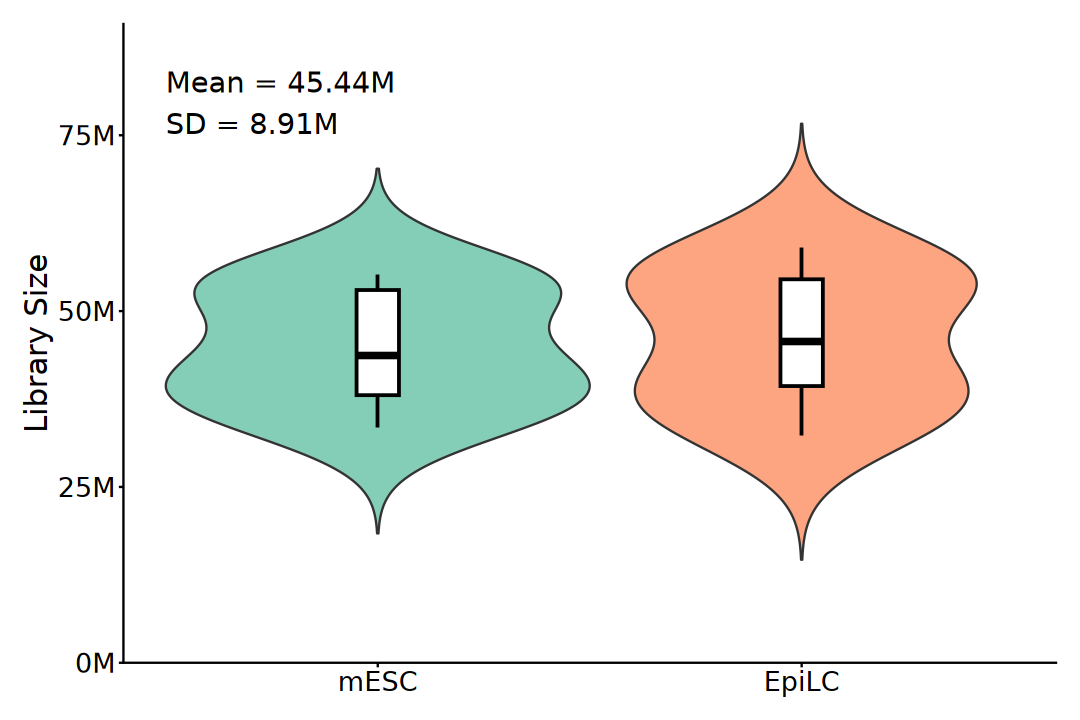

In [42]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(plot_df, aes(x = Cell, y = librarySize)) +
    geom_violin(
        aes(fill = Cell), width = 1, alpha = 0.8,
        trim = FALSE, show.legend = FALSE) +
    geom_boxplot(
        color = "black", fill = "white", width = 0.1, 
        linewidth = 0.8, show.legend = FALSE) +
    annotate(
        geom = "text", x = .5, y = max(plot_df$librarySize) * 1.4,
        label = paste0("Mean = ", round(mean(plot_df$librarySize) / 1e6 , 2), "M"),
        hjust = 0, size = 6) +
    annotate(
        geom = "text", x = .5, y = max(plot_df$librarySize) * 1.3,
        label = paste0("SD = ", round(sd(plot_df$librarySize) * 1e-6 , 2), "M"),
        hjust = 0, size = 6) +
    scale_y_continuous(
        labels = scales::label_number(scale = 1e-6, suffix = "M"), 
        limits = c(0, NA), expand = expansion(mult = c(0, 0.1))) +
    scale_fill_brewer(palette = "Set2") +
    labs(x = NULL, y = "Library Size") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

## 2). PCA

In [43]:
top_var_idx <- norm_mat |>
    rowSds() |>
    # (\(m) rowSds(m) / rowMeans2(m))() |> # CV
    tibble::enframe(name = "row", value = "sd") |>
    slice_max(order_by = sd, n = 2000) |>
    pull(row)
# CV can eliminate the bias that "high abundance tends to have large variance".

In [44]:
pca_res <- norm_mat[top_var_idx, ] |> t() |> 
    prcomp(center = TRUE, scale. = FALSE)

per_var <- round(100 * pca_res$sdev^2 / sum(pca_res$sdev^2), 2)

pca_df <- merge(pca_res$x, colData(eSet), by = "row.names")

In [45]:
p1 <- ggplot(pca_df, aes(PC1, PC2)) +
    geom_point(aes(color = Cell), size = 5) +
    scale_color_brewer(palette = "Set1") +
    labs(
        title = bquote("PCA for" ~ -log[2](TPM+1)), 
        x = paste0("PC1: ", per_var[1], "% variance"),
        y = paste0("PC2: ", per_var[2], "% variance")) +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [46]:
pca_res <- plotPCA(
    rld, intgroup = c("Cell", "Replicate"), 
    ntop = 2000, returnData = TRUE)

per_var <- round(100 * attr(pca_res, "percentVar"))

using ntop=2000 top features by variance



In [47]:
p2 <- ggplot(pca_res, aes(PC1, PC2)) +
    geom_point(aes(color = Cell), size = 5) +
    scale_color_brewer(palette = "Set1") +
    labs(
        title = "PCA for rlog", 
        x = paste0("PC1: ", per_var[1], "% variance"),
        y = paste0("PC2: ", per_var[2], "% variance")) +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [48]:
# Generalized principal component analysis (GLM-PCA)
# suppressPackageStartupMessages(library(glmpca))
gpca <- glmpca::glmpca(assay(eSet)[top_var_idx, ], L = 2)

gpca_df <- merge(gpca$factors, colData(eSet), by = "row.names")

In [49]:
p3 <- ggplot(gpca_df, aes(dim1, dim2)) +
    geom_point(aes(color = Cell), size = 5) +
    scale_color_brewer(palette = "Set1") +
    labs(title = "GLM-PCA for raw count", x = "PC1", y = "PC2") +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

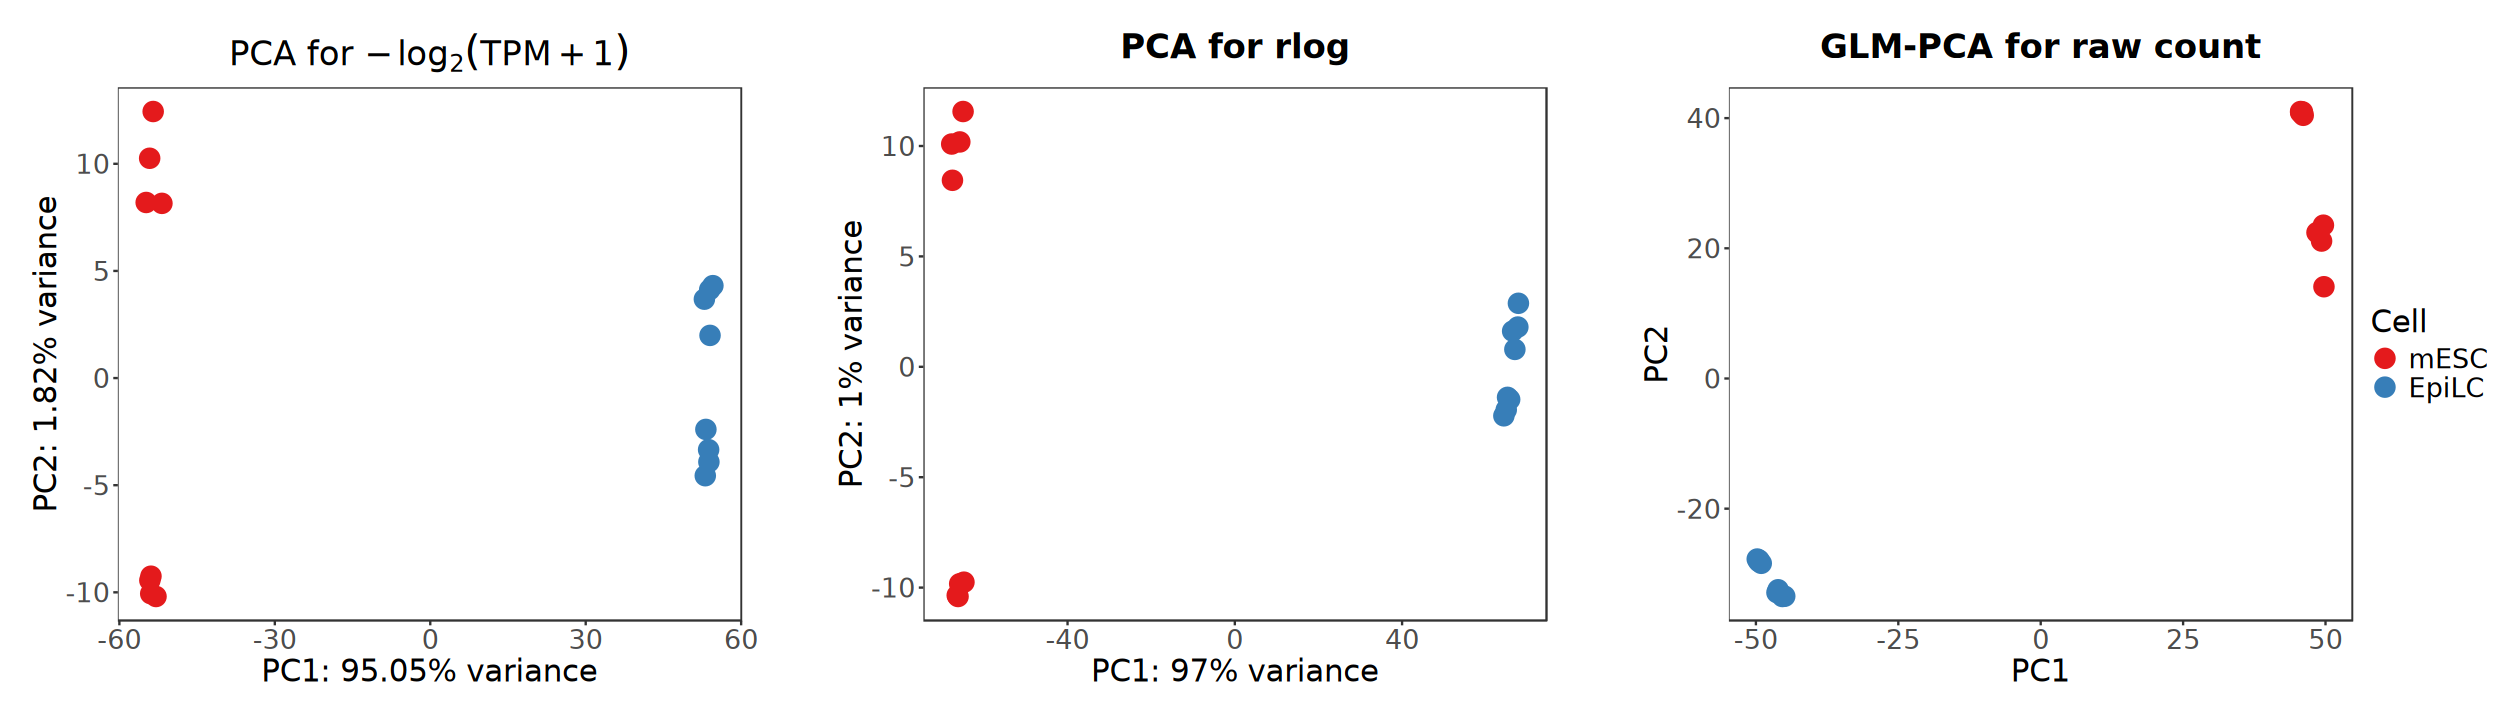

In [50]:
options(repr.plot.width = 21, repr.plot.height = 6)

p1 + plot_spacer() + p2 + plot_spacer() + p3 +
    plot_layout(nrow = 1, guides = "collect", 
                widths = c(1, 0.05, 1, 0.05, 1))

## 3). MDS

> Multidimensional scaling

In [51]:
dist_mat <- norm_vs[top_var_idx, ] |> t() |> dist()

mds <- colData(eSet) |> as.data.frame() |>
    cbind(cmdscale(as.matrix(dist_mat)))

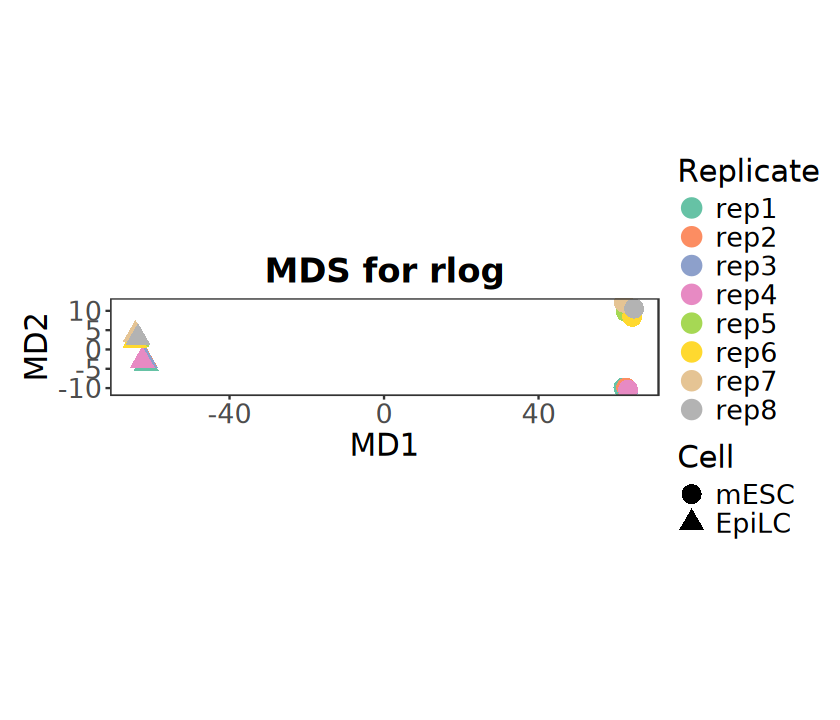

In [52]:
options(repr.plot.width = 7, repr.plot.height = 6)

ggplot(mds, aes(x = `1`, y = `2`)) +
    geom_point(aes(color = Replicate, shape = Cell), size = 5) +
    scale_color_brewer(palette = "Set2") +
    coord_fixed() + 
    # ggtitle(bquote("MDS for" ~ -log[2](TPM+1))) + 
    ggtitle("MDS for rlog") + 
    labs(x = "MD1", y = "MD2") +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

## 4). PCoA

> Principal coordinate analysis

In [53]:
# 1. Calculate Bray-Curtis distance on the transposed count matrix
dist_mat <- norm_vs[top_var_idx, ] |> t() |> 
    vegan::vegdist(method = "bray")

# 2. Run PCoA
pcoa_res <- cmdscale(dist_mat, k = 2, eig = TRUE)

# 3. Prepare data for plot
pcoa_df <- merge(pcoa_res$points, colData(eSet), by = "row.names")

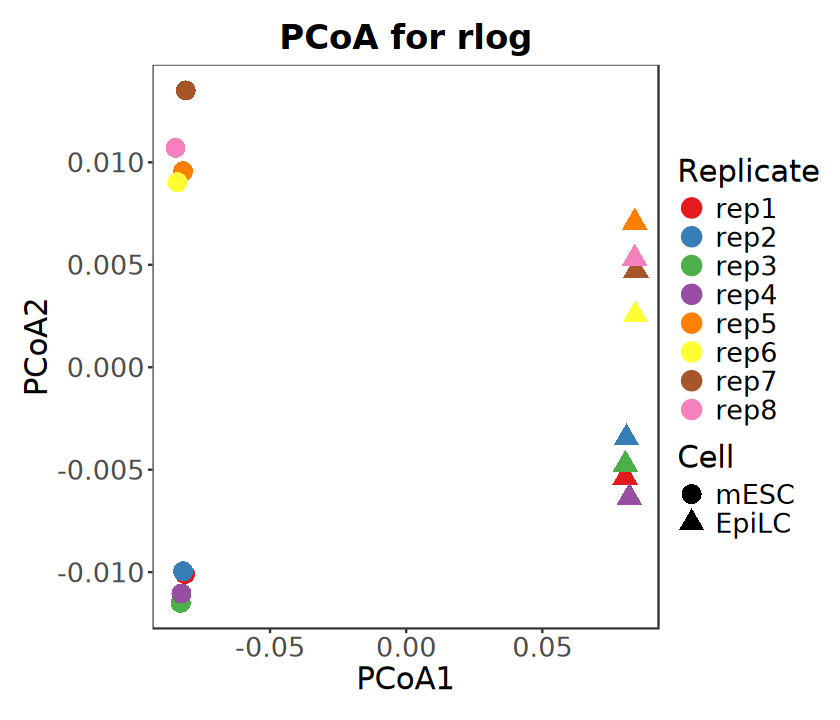

In [54]:
options(repr.plot.width = 7, repr.plot.height = 6)

ggplot(pcoa_df, aes(x = V1, y = V2)) +
    geom_point(aes(color = Replicate, shape = Cell), size = 5) +
    scale_color_brewer(palette = "Set1") +
    # coord_fixed() + 
    # ggtitle(bquote("PCoA for" ~ -log[2](TPM+1))) + 
    ggtitle("PCoA for rlog") + 
    labs(x = "PCoA1", y = "PCoA2") +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

## 5). Sample Distance

In [55]:
ac <- colData(eSet) |> as.data.frame() |>
    dplyr::select(Replicate, Cell)

In [56]:
group_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(eSet$Cell)),
    levels(eSet$Cell))
replicate_colors <- setNames(
    scales::brewer_pal(palette = "Set2")(nlevels(eSet$Replicate)),
    levels(eSet$Replicate))

anno_colors <- list(
    Cell = group_colors,
    Replicate = replicate_colors)

colors <- colorRampPalette(brewer.pal(9, "Blues"))(255)

In [57]:
dist_mat <- norm_vs[top_var_idx, ] |> t() |> dist()

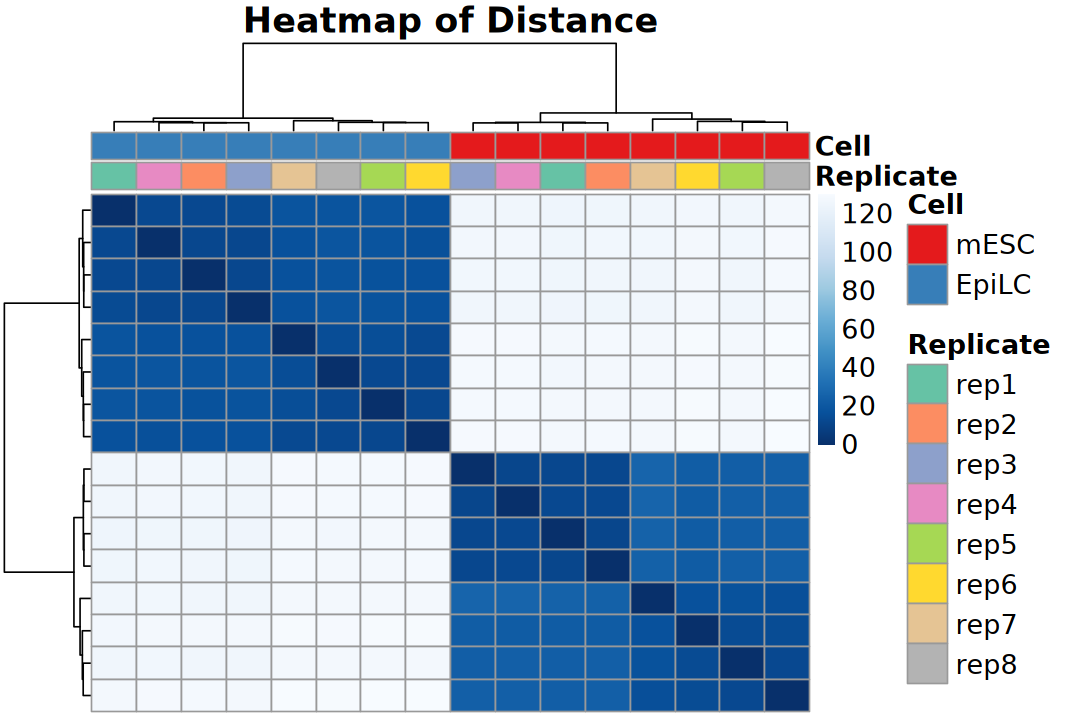

In [58]:
options(repr.plot.width = 9, repr.plot.height = 6)

pheatmap::pheatmap(
    as.matrix(dist_mat),
    clustering_distance_rows = dist_mat,
    clustering_distance_cols = dist_mat,
    annotation_col = ac, col = rev(colors), 
    annotation_colors = anno_colors,
    main = "Heatmap of Distance", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

In [59]:
# This measure of dissimilarity between counts also takes the inherent variance structure 
# of counts into consideration when calculating the distances between samples. 
# The PoissonDistance function takes the original count matrix (not normalized) with samples
# as rows instead of columns, so we need to transpose the counts in dds.
# Calculating sample distances is to use the Poisson Distance

# suppressPackageStartupMessages(library(PoiClaClu))
poisd <- assay(eSet)[top_var_idx, ] |> t() |> 
    PoiClaClu::PoissonDistance()

dist_mat <- poisd$dd |> as.matrix()

colnames(dist_mat) <- colnames(eSet)

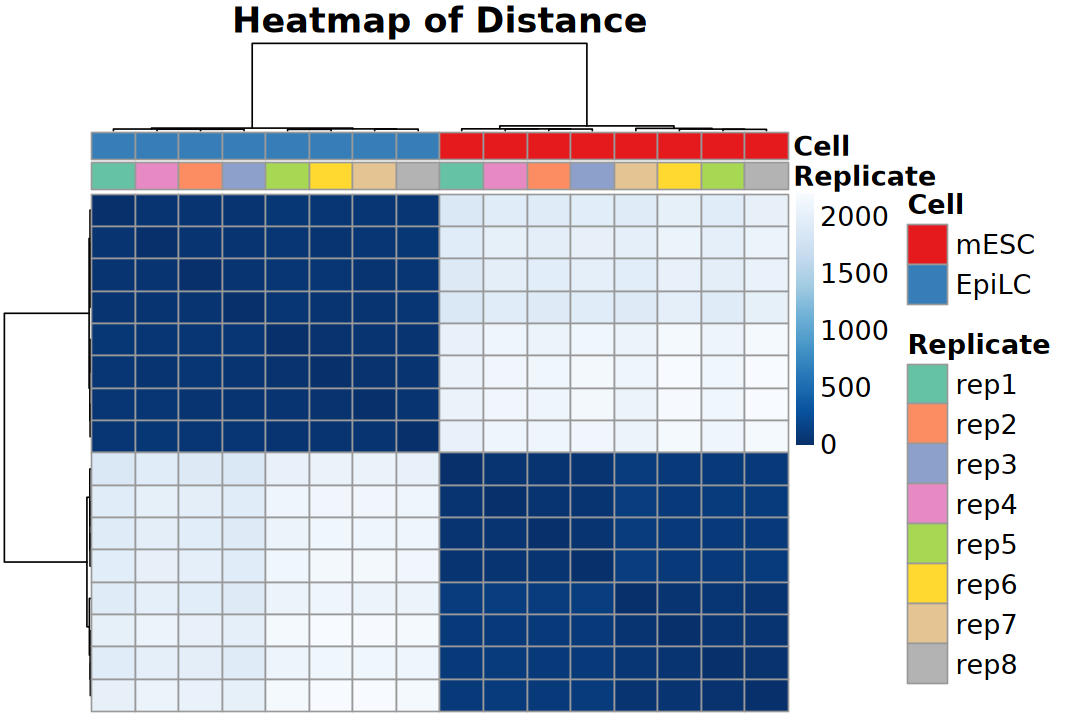

In [60]:
options(repr.plot.width = 9, repr.plot.height = 6)

pheatmap::pheatmap(
    as.matrix(dist_mat),
    clustering_distance_rows = poisd$dd,
    clustering_distance_cols = poisd$dd,
    annotation_col = ac, col = rev(colors), 
    annotation_colors = anno_colors,
    main = "Heatmap of Distance", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

## 6). Sample Correlation

In [61]:
cor_mat <- cor(norm_vs[top_var_idx, ], method = "spearman")

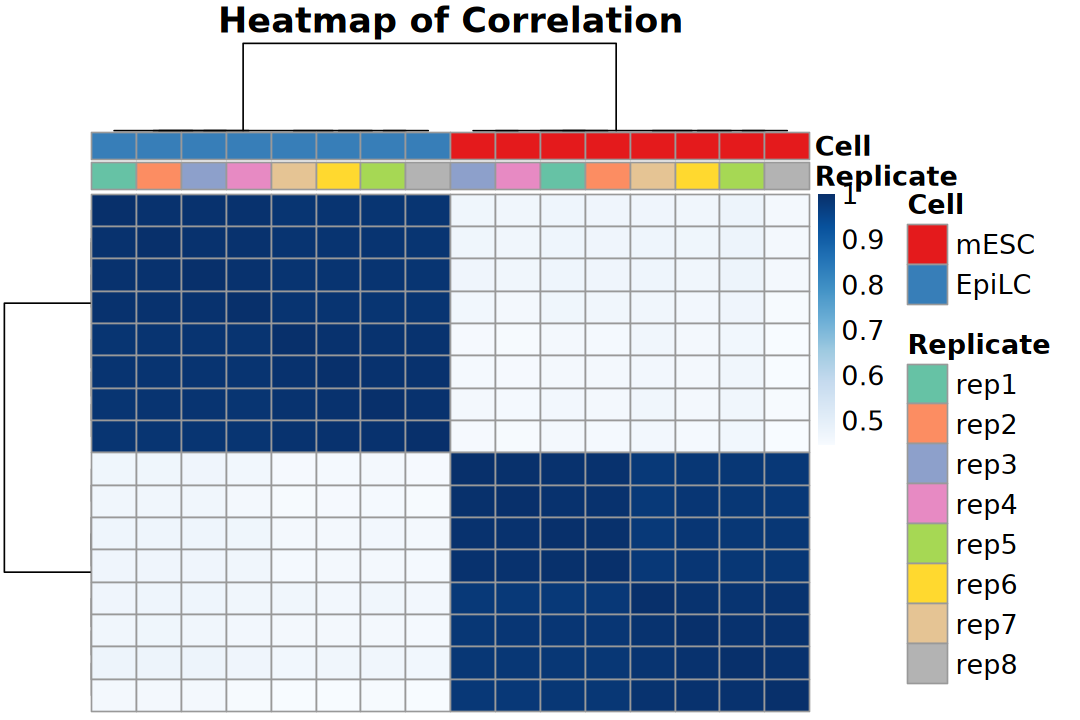

In [62]:
options(repr.plot.width = 9, repr.plot.height = 6)

pheatmap::pheatmap(
    as.matrix(cor_mat), 
    clustering_distance_rows = "correlation",
    clustering_distance_cols = "correlation",
    annotation_col = ac, col = colors, 
    annotation_colors = anno_colors,
    main = "Heatmap of Correlation", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

## 7). Heatmap

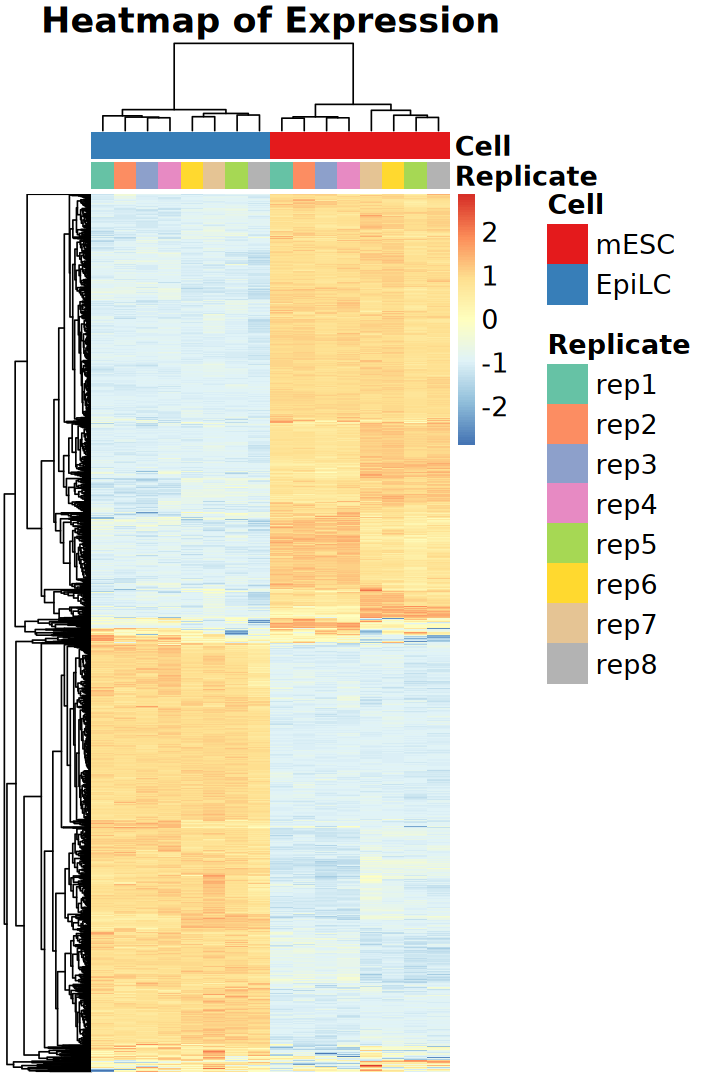

In [63]:
options(repr.plot.width = 6, repr.plot.height = 9)

pheatmap::pheatmap(
    norm_mat[top_var_idx, ], scale = "row", 
    annotation_col = ac, 
    annotation_colors = anno_colors, 
    main = "Heatmap of Expression", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

# 5. DEGs

In [64]:
logfc_cutoff <- log2(4)
p_cutoff <- 0.01

## 1). DESeq2

> median of ratios for normalization

In [65]:
design(dds)

~Cell

In [66]:
dds <- DESeq(dds)

using pre-existing size factors

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing

-- replacing outliers and refitting for 4 genes
-- DESeq argument 'minReplicatesForReplace' = 7 
-- original counts are preserved in counts(dds)

estimating dispersions

fitting model and testing



In [67]:
resultsNames(dds)

[1] "Intercept"          "Cell_EpiLC_vs_mESC"

### a). Standard

In [68]:
res <- results(dds, lfcThreshold = logfc_cutoff, alpha = p_cutoff)
# res <- results(
#     dds, name = "Cell_EpiLC_vs_mESC", 
#     lfcThreshold = logfc_cutoff, alpha = p_cutoff)
# res <- results(
#     dds, contrast = c("Group", "EpiLC", "mESC"), 
#     lfcThreshold = logfc_cutoff, alpha = p_cutoff)
summary(res)


out of 17154 with nonzero total read count
adjusted p-value < 0.01
LFC > 2.00 (up)    : 1097, 6.4%
LFC < -2.00 (down) : 757, 4.4%
outliers [1]       : 0, 0%
low counts [2]     : 0, 0%
(mean count < 7)
[1] see 'cooksCutoff' argument of ?results
[2] see 'independentFiltering' argument of ?results



In [69]:
deseq2_result <- res |> as.data.frame() |> 
    rownames_to_column("gene_id") |>
    dplyr::rename(logFC = log2FoldChange) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS"))) |>
    left_join(
        rowData(dds) |> 
            as.data.frame() |> 
            dplyr::select(symbol, type, basepairs) |>
            rownames_to_column("gene_id"), 
        by = "gene_id") |>
    column_to_rownames("gene_id")

table(deseq2_result$result)


   Up  Down    NS 
 1097   757 15300 

### b). LFC Shrink

> Shrinkage of effect size (LFC estimates) is useful for visualization and ranking of genes.

In [70]:
res_lfc <- lfcShrink(dds, coef = "Cell_EpiLC_vs_mESC", type = "apeglm")
summary(res_lfc)

using 'apeglm' for LFC shrinkage. If used in published research, please cite:
    Zhu, A., Ibrahim, J.G., Love, M.I. (2018) Heavy-tailed prior distributions for
    sequence count data: removing the noise and preserving large differences.
    Bioinformatics. https://doi.org/10.1093/bioinformatics/bty895




out of 17154 with nonzero total read count
adjusted p-value < 0.1
LFC > 0 (up)       : 6688, 39%
LFC < 0 (down)     : 6376, 37%
outliers [1]       : 0, 0%
low counts [2]     : 0, 0%
(mean count < 7)
[1] see 'cooksCutoff' argument of ?results
[2] see 'independentFiltering' argument of ?results



In [71]:
deseq2_lfc_result <- res_lfc |> as.data.frame() |> 
    rownames_to_column("gene_id") |>
    dplyr::rename(logFC = log2FoldChange) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS"))) |>
    left_join(
        rowData(dds) |> 
            as.data.frame() |> 
            dplyr::select(symbol, type, basepairs) |>
            rownames_to_column("gene_id"), 
        by = "gene_id") |>
    column_to_rownames("gene_id")

table(deseq2_lfc_result$result)


   Up  Down    NS 
 1497  1070 14587 

### Evaluate DEGs

In [72]:
suppressPackageStartupMessages(library(ggVennDiagram))

In [73]:
genes_up <- list(
    raw = deseq2_result |> filter(result == "Up") |> 
        pull(symbol) |> unique(),
    lfc = deseq2_lfc_result |> filter(result == "Up") |> 
        pull(symbol) |> unique())

genes_down <- list(
    raw = deseq2_result |> filter(result == "Down") |> 
        pull(symbol) |> unique(),
    lfc = deseq2_lfc_result |> filter(result == "Down") |> 
        pull(symbol) |> unique())

In [74]:
p1 <- ggVennDiagram(
    genes_up, set_color = "grey", set_size = 6, 
    label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

p2 <- ggVennDiagram(
    genes_down, set_color = "grey", set_size = 6, 
    label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

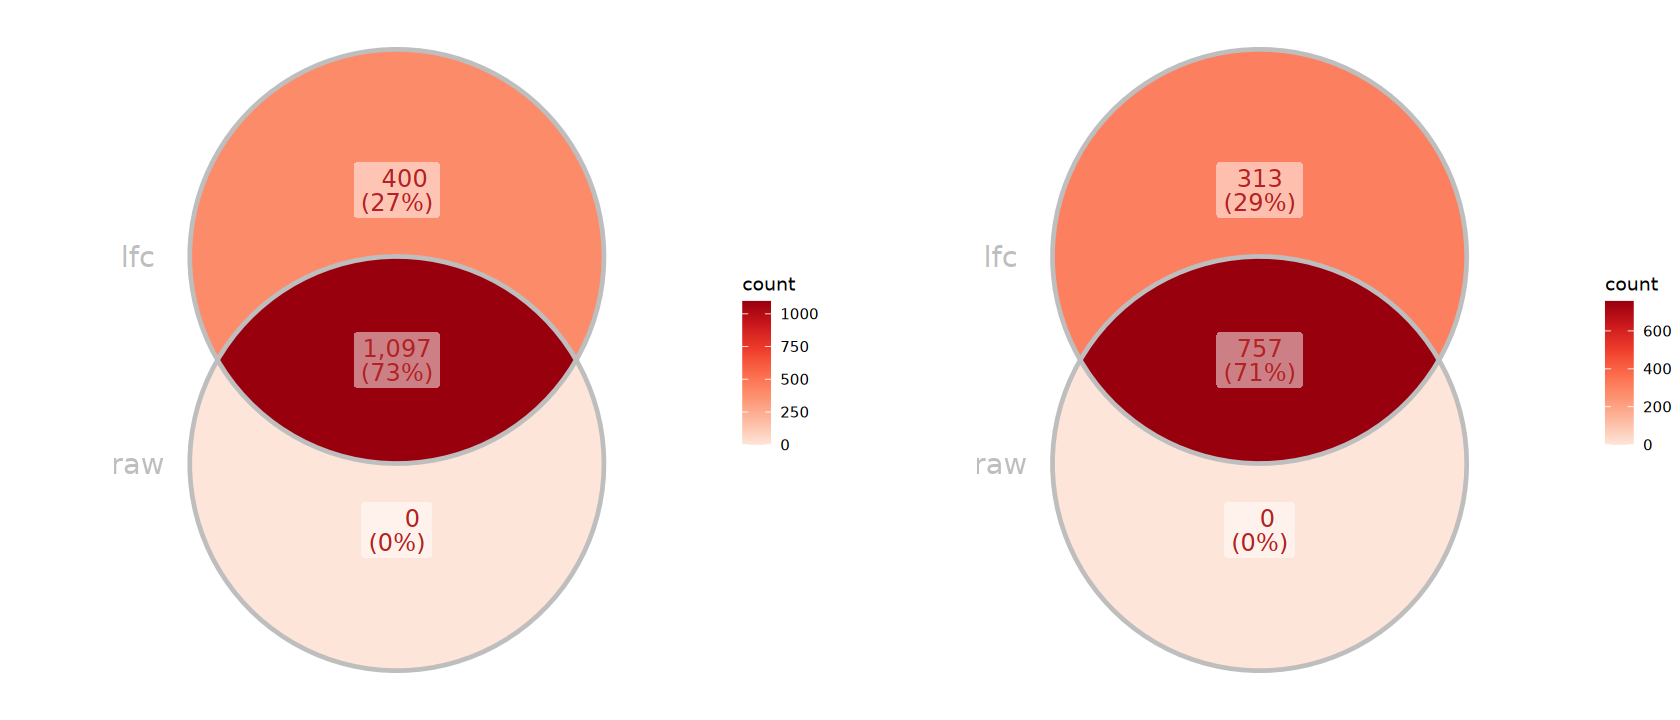

In [75]:
options(repr.plot.width = 14, repr.plot.height = 6)

p1 + plot_spacer() + p2 +
    plot_layout(nrow = 1, widths = c(1, 0.05, 1))

## 2). edgeR

> Trimmed Mean of M-values (TMM)

| Pipeline | Advantages | Application | Estimating dispersions | Fitting model | Testing methods | Notes |
| - | - | - | - | - | - | - |
| Classic pipeline (edgeR v1) | - | Single factor design | quantile-adjusted conditional maximum likelihood (qCML) method | Negative binomial model | Exact test (like Fisher’s exact test) | - |
| Negative binomial GLM framework (edgeR v2) | - | Multiple factors design | Cox-Reid profile-adjusted likelihood (CR) method | Negative binomial - Generalized linear model (NB GLM) | Likelihood ratio test (LRT) | - |
| Quasi-likelihood pipeline (edgeR v3) | Robustness and highly reliable false discovery rate (FDR) control | Multiple factors design | Cox-Reid profile-adjusted likelihood (CR) method | only the trended NB dispersions are used in fitting the QL GLM | Quasi-likelihood F-test (QLF) | - |
| Quasi-likelihood pipeline (edgeR v4) | Robustness and highly reliable false discovery rate (FDR) control | Multiple factors design | Estimates a constant NB dispersion based on the most highly expressed genes | only the trended NB dispersions are used in fitting the QL GLM | Quasi-likelihood F-test (QLF) | Default and Recommended approach in edgeR |

### a). Classic pipeline

In [76]:
dgel_classic <- estimateDisp(dgel)
# # 1. Estimate common dispersion
# dgel <- estimateCommonDisp(dgel)
# # 2. Estimate tagwise dispersions
# dgel <- estimateTagwiseDisp(dgel)

Using classic mode.



In [77]:
# exact test
et <- exactTest(dgel_classic, pair = c("mESC", "EpiLC"))

In [78]:
edger_classic_result <- topTags(et, n = Inf) |> 
    as.data.frame() |> 
    dplyr::rename(padj = FDR, pvalue = PValue) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS")))

table(edger_classic_result$result)


   Up  Down    NS 
 1507  1084 14385 

### b). Negative binomial GLM framework

In [79]:
design <- model.matrix(~ group, data = dgel$samples) # include intercept

In [80]:
dgel_nbglm <- estimateDisp(dgel, design)
# # Estimate common dispersion
# dgel <- estimateGLMCommonDisp(dge, design)
# # Estimate trended dispersions
# dgel <- estimateGLMTrendedDisp(dgel, design)
# # Estimate tagwise dispersions
# dgel <- estimateGLMTagwiseDisp(dgel, design)

In [81]:
# likelihood ratio test
fit <- glmFit(dgel_nbglm, design)
lrt <- glmLRT(fit, coef = 2)

In [82]:
edger_glm_lrt_result <- topTags(lrt, n = Inf) |>
    as.data.frame() |> 
    dplyr::rename(padj = FDR, pvalue = PValue) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS")))

table(edger_glm_lrt_result$result)


   Up  Down    NS 
 1507  1084 14385 

### c). Quasi-likelihood pipeline (edgeR v3)

In [83]:
design <- model.matrix(~ group, data = dgel$samples) # include intercept

In [84]:
dgel_nbglm <- estimateDisp(dgel, design)

In [85]:
# quasi-likelihood (QL) F-test
fit <- glmQLFit(dgel_nbglm, design)
qlf <- glmQLFTest(fit, coef = 2)

In [86]:
edger_glm_qlf_result <- topTags(qlf, n = Inf) |>
    as.data.frame() |> 
    dplyr::rename(padj = FDR, pvalue = PValue) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS")))

table(edger_glm_qlf_result$result)


   Up  Down    NS 
 1503  1085 14388 

### d). Quasi-likelihood pipeline (edgeR v4)

In [87]:
design <- model.matrix(~ group, data = dgel$samples) # include intercept

In [88]:
# quasi-likelihood (QL) F-test
fit <- glmQLFit(dgel, design)
qlf <- glmQLFTest(fit, coef = 2)

In [89]:
edger_glm_qlf_v4_result <- topTags(qlf, n = Inf) |>
    as.data.frame() |> 
    dplyr::rename(padj = FDR, pvalue = PValue) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS")))

table(edger_glm_qlf_v4_result$result)


   Up  Down    NS 
 1503  1085 14388 

### Evaluate DEGs

In [90]:
suppressPackageStartupMessages(library(ggVennDiagram))

In [91]:
genes_up <- list(
    classic = edger_classic_result |> filter(result == "Up") |> 
        pull(symbol) |> unique(),
    glm_lrt = edger_glm_lrt_result |> filter(result == "Up") |> 
        pull(symbol) |> unique(),
    glm_qlf = edger_glm_qlf_result |> filter(result == "Up") |> 
        pull(symbol) |> unique(),
    glm_v4 = edger_glm_qlf_v4_result |> filter(result == "Up") |> 
        pull(symbol) |> unique())

genes_down <- list(
    classic = edger_classic_result |> filter(result == "Down") |> 
        pull(symbol) |> unique(),
    glm_lrt = edger_glm_lrt_result |> filter(result == "Down") |> 
        pull(symbol) |> unique(),
    glm_qlf = edger_glm_qlf_result |> filter(result == "Down") |> 
        pull(symbol) |> unique(),
    glm_v4 = edger_glm_qlf_v4_result |> filter(result == "Down") |> 
        pull(symbol) |> unique())

In [92]:
p1 <- ggVennDiagram(
    genes_up, set_color = "grey", set_size = 6, 
    label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

p2 <- ggVennDiagram(
    genes_down, set_color = "grey", set_size = 6, 
    label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

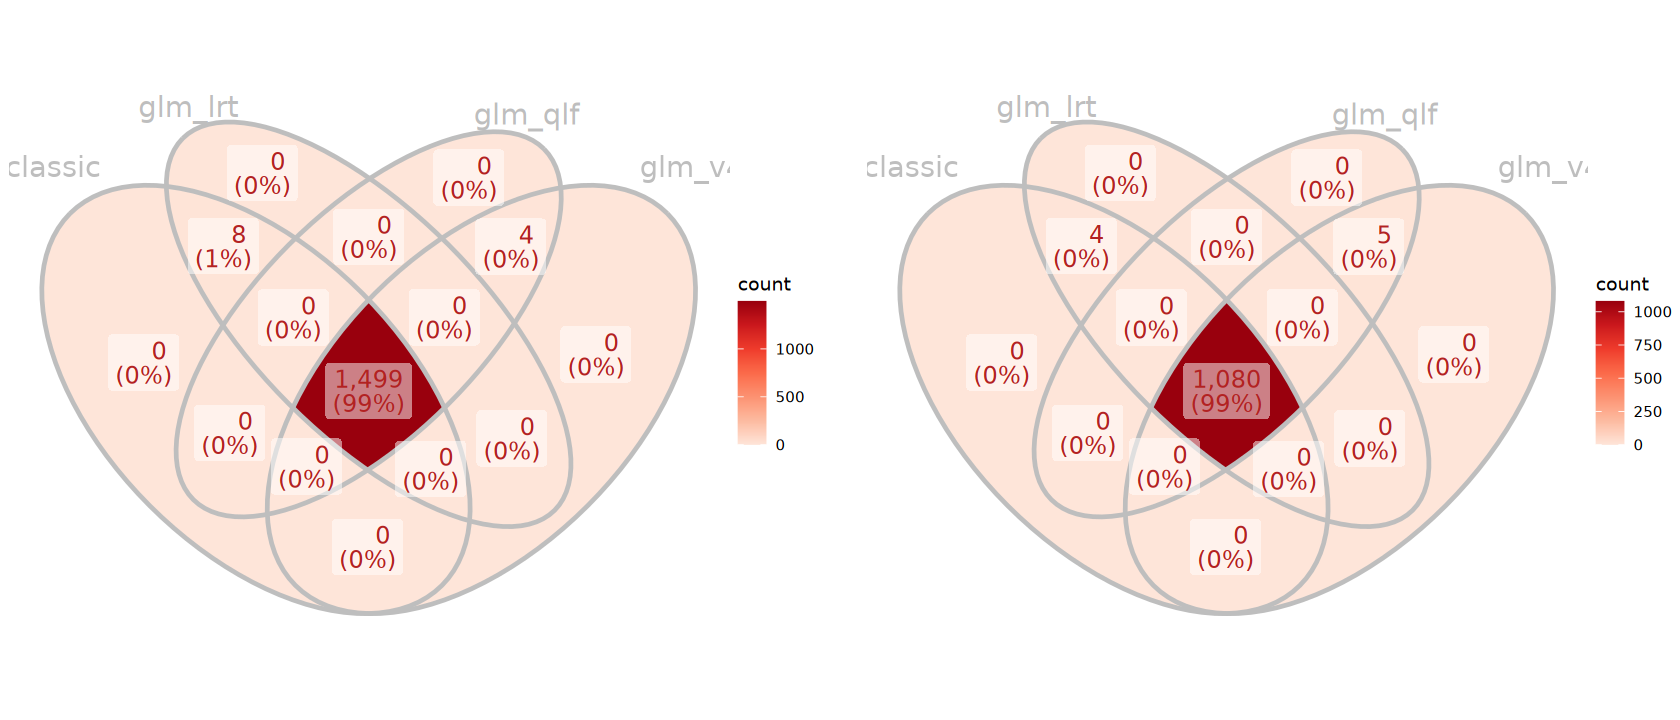

In [93]:
options(repr.plot.width = 14, repr.plot.height = 6)

p1 + plot_spacer() + p2 +
    plot_layout(nrow = 1, widths = c(1, 0.05, 1))

## 3). limma

> In the limma approach to RNA-seq, read counts are converted to log2-counts-per-million (logCPM), and the mean-variance relationship is modeled either with precision weights or with an empirical Bayes prior trend. The precision weights approach is called “voom,” and the prior trend approach is called “limma-trend.”

### a). limma-trend

> If the sequencing depth is fairly consistent across the RNA samples, then the simplest and most reliable method for differential expression is to use limma-trend. This method usually works well if the ratio of the largest library size to the smallest is no more than about 3-fold. Few literature uses.

In [94]:
design <- model.matrix(~ group, data = dgel$samples)

In [95]:
logCPM <- cpm(dgel, normalized.lib.sizes = TRUE, log = TRUE)

In [96]:
# Linear Model for Series of Arrays
fit <- lmFit(logCPM, design)
# Empirical Bayes Statistics for Differential Expression
efit <- eBayes(fit, trend = TRUE)

In [ ]:
limma_trend_result <- topTable(efit, coef = 2, number = Inf) |> 
    as.data.frame() |> 
    rownames_to_column("gene_id") |>
    dplyr::rename(padj = adj.P.Val, pvalue = P.Value) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS"))) |>
    left_join(
        dgel$genes |> rownames_to_column("gene_id"), 
        by = "gene_id") |>
    column_to_rownames("gene_id")

table(limma_trend_result$result)


   Up  Down    NS 
 1469  1043 14464 

### b). limma-voom

> When library sizes vary significantly between samples, the voom approach is technically more powerful than limma-trend.

In [98]:
design <- model.matrix(~ group, data = dgel$samples)

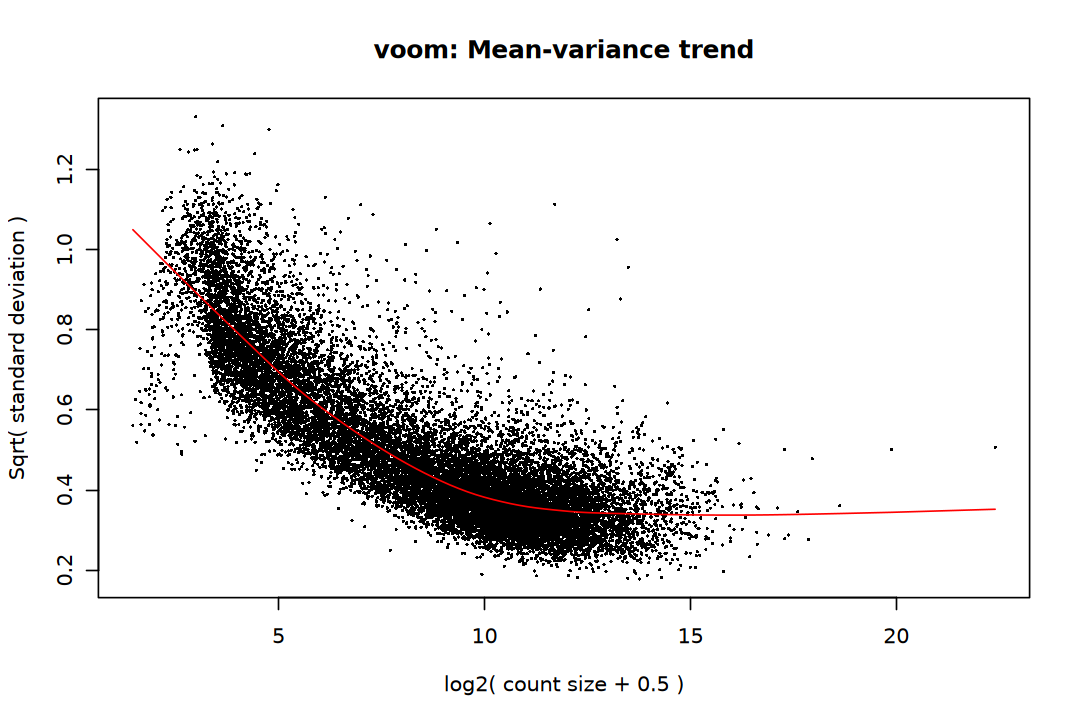

In [99]:
options(repr.plot.width = 9, repr.plot.height = 6)

norm_v <- voom(dgel, design, plot = TRUE)

In [100]:
# Linear Model for Series of Arrays
fit <- lmFit(norm_v, design)
# Empirical Bayes Statistics for Differential Expression
efit <- eBayes(fit)

In [101]:
limma_voom_result <- topTable(efit, coef = 2, number = Inf) |> 
    as.data.frame() |> 
    dplyr::rename(padj = adj.P.Val, pvalue = P.Value) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS")))

table(limma_voom_result$result)


   Up  Down    NS 
 1542  1081 14353 

### c). voomLmFit

> In recent versions of limma and edgeR, we now recommend voomLmFit as the preferred interface for RNA-seq analyses, replacing voom, lmFit, and voomWithQualityWeights. voomLmFit ensures unbiased estimation of the residual variances, even for genes that have no counts at all in some experimental conditions.
> - voomLmFit = voom transform + lmFit with weights

In [102]:
design <- model.matrix(~ group, data = dgel$samples)

In [103]:
# sample.weights = TRUE: estimating the empirical sample quality weights
fit <- voomLmFit(dgel, design = design, sample.weights = TRUE)
efit <- eBayes(fit)

First sample weights (min/max) 0.4851724/1.6946325

Final sample weights (min/max) 0.4824052/1.6926177



In [104]:
limma_voomLmFit_result <- topTable(efit, coef = 2, number = Inf) |> 
    as.data.frame() |> 
    dplyr::rename(padj = adj.P.Val, pvalue = P.Value) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS")))

table(limma_voomLmFit_result$result)


   Up  Down    NS 
 1556  1085 14335 

### Evaluate DEGs

In [105]:
suppressPackageStartupMessages(library(ggVennDiagram))

In [ ]:
genes_up <- list(
    trend = limma_trend_result |> filter(result == "Up") |> 
        pull(symbol) |> unique(),
    voom = limma_voom_result |> filter(result == "Up") |> 
        pull(symbol) |> unique(),
    voom_wight = limma_voomLmFit_result |> filter(result == "Up") |> 
        pull(symbol) |> unique())

genes_down <- list(
    trend = limma_trend_result |> filter(result == "Down") |> 
        pull(symbol) |> unique(),
    voom = limma_voom_result |> filter(result == "Down") |> 
        pull(symbol) |> unique(),
    voom_wight = limma_voomLmFit_result |> filter(result == "Down") |> 
        pull(symbol) |> unique())

In [107]:
p1 <- ggVennDiagram(
    genes_up, set_color = "grey", set_size = 6, 
    label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

p2 <- ggVennDiagram(
    genes_down, set_color = "grey", set_size = 6, 
    label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

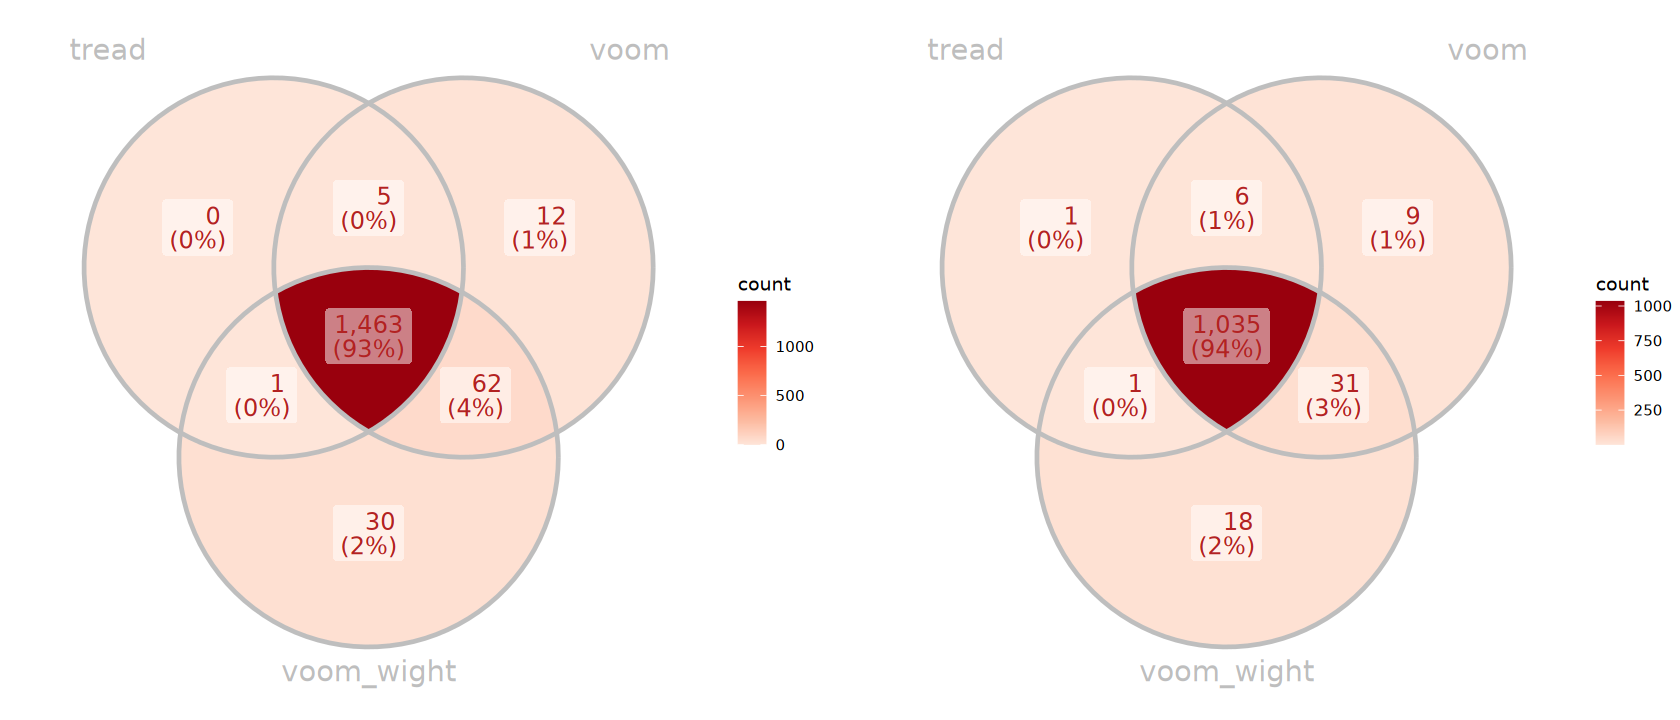

In [108]:
options(repr.plot.width = 14, repr.plot.height = 6)

p1 + plot_spacer() + p2 +
    plot_layout(nrow = 1, widths = c(1, 0.05, 1))

## DEGs Evaluation

In [109]:
add_label <- function(res, symbol_col = "symbol"){
    res |>
        tibble::rownames_to_column("gene_id") |>
        dplyr::group_by(result) |>
        dplyr::arrange(padj, dplyr::desc(abs(logFC)), .by_group = TRUE) |>
        dplyr::mutate(
            label = dplyr::if_else(
                result %in% c("Up", "Down") & dplyr::row_number() <= 10,
                .data[[symbol_col]], NA_character_)) |>
        dplyr::ungroup() |>
        tibble::column_to_rownames("gene_id")
}

In [110]:
deseq2_result <- add_label(deseq2_lfc_result, symbol_col = "symbol")
edger_result <- add_label(edger_glm_qlf_result, symbol_col = "symbol")
limma_result <- add_label(limma_voom_result, symbol_col = "symbol")

### P-value Histogram

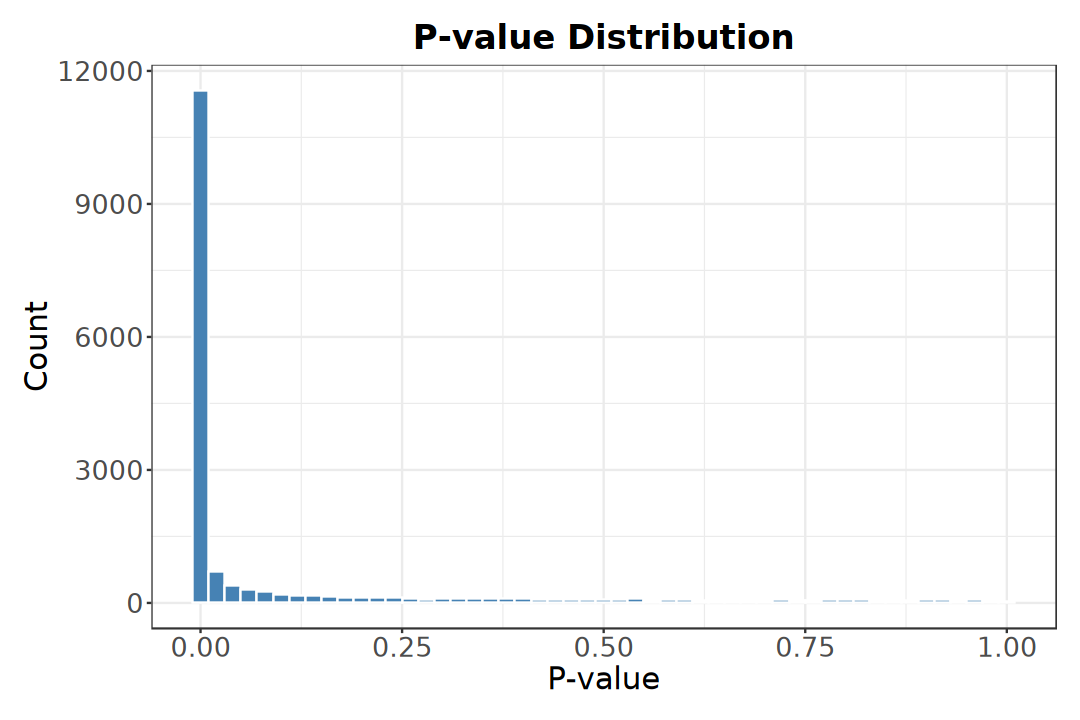

In [111]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(deseq2_result, aes(x = pvalue)) +
    geom_histogram(binwidth = 0.02, fill = "steelblue", color = "white") +
    labs(
        title = "P-value Distribution", 
        x = "P-value", y = "Count") +
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

### MA Plot

> - Mean-Difference plot
> - Bland-Altman plot

In [112]:
ggplot_maplot <- function(plot_df, col, log = FALSE, title = NULL) {
    if(log) {
        x_vals <- log2(plot_df[[col]] + 1)
    } else {
        x_vals <- plot_df[[col]]
    }

    max_logfc <- plot_df$logFC |> abs() |> 
        max(na.rm = TRUE) |> ceiling()

    ggplot(plot_df, aes(x = x_vals, y = logFC)) +
        geom_point(
            aes(color = result, size = result), na.rm = TRUE) +
        geom_hline(
            yintercept = c(-logfc_cutoff, logfc_cutoff),
            linetype = "dashed", color = "gray") +
        geom_text_repel(
            aes(label = label), color = "black", na.rm = TRUE, size = 6, 
            min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf) +
        scale_y_continuous(limits = c(-max_logfc, max_logfc)) +
        scale_color_manual(
            values = c(Up = "LightCoral", Down = "SkyBlue", NS = "gray")) +
        scale_size_manual(
            values = c(Up = 2, Down = 2, NS = 1), guide = "none") +
        guides(
            color = guide_legend(override.aes = list(size = 6))) +
        labs(
            title = paste0("MA plot (", title,")"), , color = "DEG",
            x = "Mean Expression", y = "log2FC") +
        theme_test() + 
        theme(
            plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
            plot.margin = unit(c(1, 1, 1, 1), "line"),
            legend.title = element_text(size = 18), 
            legend.text = element_text(size = 16),
            axis.title = element_text(size = 18),
            axis.text = element_text(size = 16))
}

In [113]:
p1 <- ggplot_maplot(deseq2_result, col = "baseMean", log = TRUE, title = "DESeq2")
p2 <- ggplot_maplot(edger_result, col = "logCPM", title = "edgeR")
p3 <- ggplot_maplot(limma_result, col = "AveExpr", title = "limma-voom")

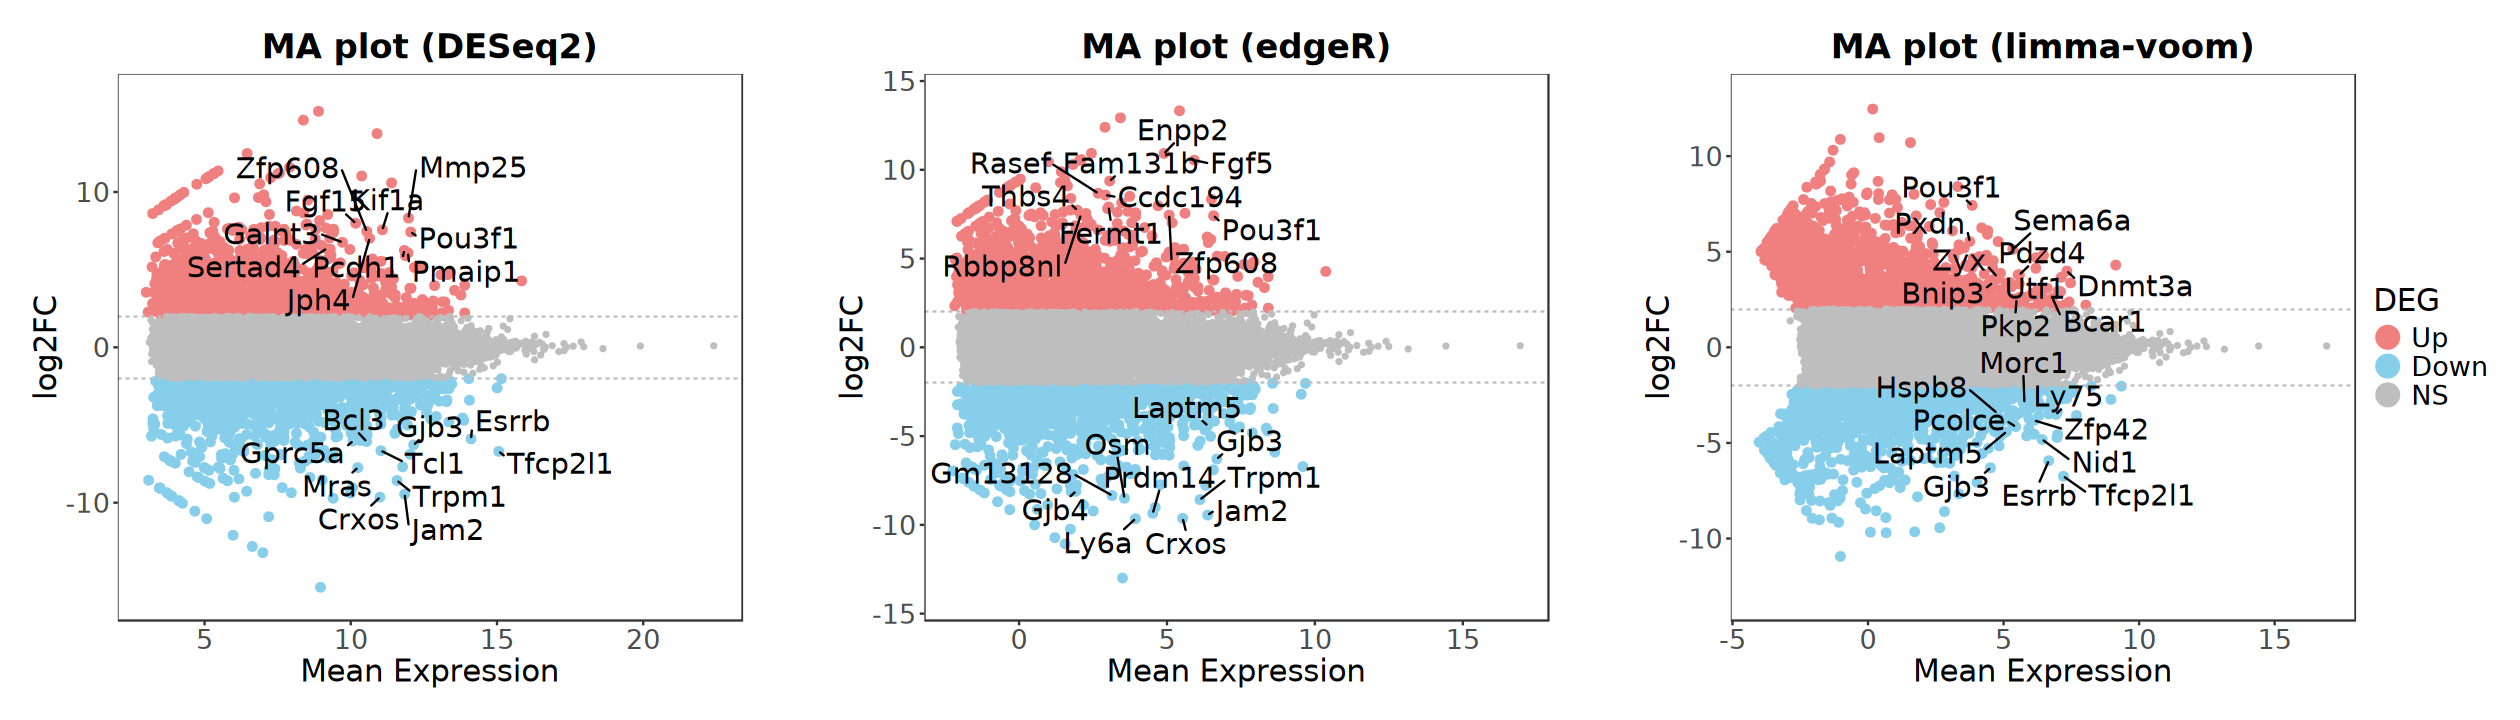

In [114]:
options(repr.plot.width = 21, repr.plot.height = 6)

p1 + plot_spacer() + p2 + plot_spacer() + p3 +
    plot_layout(
        nrow = 1, guides = "collect", 
        widths = c(1, 0.05, 1, 0.05, 1))

### Volcano

In [115]:
ggplot_volcano <- function(plot_df, title = NULL) {
    max_logfc <- plot_df$logFC |> abs() |> 
        max(na.rm = TRUE) |> ceiling()
    min_padj <- plot_df$padj |> pmax(1e-300) |> 
        (\(x) -log10(x))() |> max(na.rm = TRUE) |> 
        (\(x) ceiling(x / 5) * 5)()

    ggplot(plot_df, aes(x = logFC, y = -log10(pmax(padj, 1e-300)))) +
        geom_point(
            aes(color = result, size = result), na.rm = TRUE) +
        geom_hline(
            yintercept = -log10(p_cutoff), 
            linetype = "dashed", color = "gray") + 
        geom_vline(
            xintercept = c(-logfc_cutoff, logfc_cutoff),
            linetype = "dashed", color = "gray") +
        ggrepel::geom_text_repel(
            aes(label = label), color = "black", na.rm = TRUE, size = 4, 
            min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf) +
        scale_x_continuous(
            expand = c(0.1, 0), limits = c(-max_logfc, max_logfc)) +
        scale_y_continuous(
            expand = expansion(mult = c(0, 0.1)), limits = c(0, min_padj)) + 
        scale_color_manual(
            values = c(Up = "LightCoral", Down = "SkyBlue", NS = "gray")) +
        scale_size_manual(
            values = c(Up = 2, Down = 2, NS = 1), guide = "none") +
        labs(
            title = paste0("Volcano (", title,")"), , color = "DEG",
            x = "log2FC", y = expression(-log[10](P.adjust))) +
        guides(
            color = guide_legend(override.aes = list(size = 6))) +
        theme_test() + 
        theme(
            plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
            plot.margin = unit(c(1, 1, 1, 1), "line"),
            legend.title = element_text(size = 18), 
            legend.text = element_text(size = 16),
            axis.title = element_text(size = 18), 
            axis.text = element_text(size = 16))
}

In [116]:
p1 <- ggplot_volcano(deseq2_result, title = "DESeq2")
p2 <- ggplot_volcano(edger_result, title = "edgeR")
p3 <- ggplot_volcano(limma_result, title = "limma-voom")

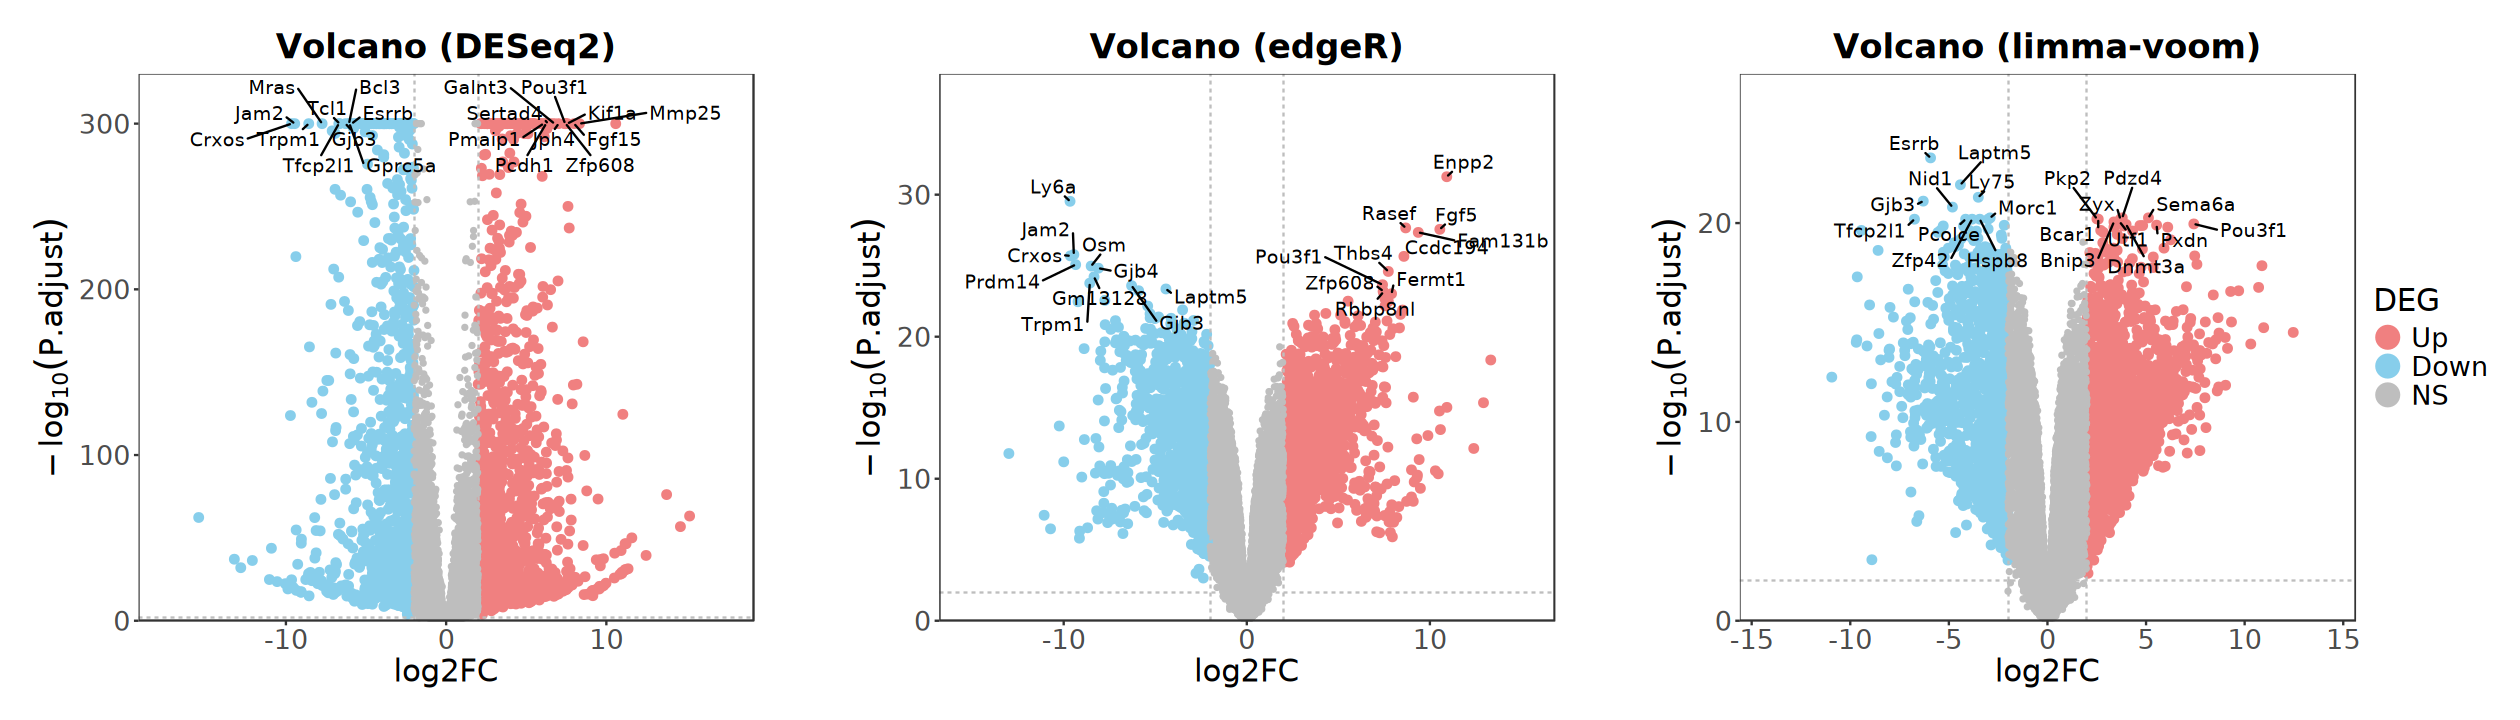

In [117]:
options(repr.plot.width = 21, repr.plot.height = 6)

p1 + plot_spacer() + p2 + plot_spacer() + p3 +
    plot_layout(
        nrow = 1, guides = "collect", 
        widths = c(1, 0.05, 1, 0.05, 1))

### Venn

In [118]:
suppressPackageStartupMessages(library(ggVennDiagram))

In [119]:
genes_up <- list(
    DESeq2 = deseq2_result |> filter(result == "Up") |> 
        pull(symbol) |> unique(),
    edgeR = edger_result |> filter(result == "Up") |> 
        pull(symbol) |> unique(),
    limma = limma_result |> filter(result == "Up") |> 
        pull(symbol) |> unique())

genes_down <- list(
    DESeq2 = deseq2_result |> filter(result == "Down") |> 
        pull(symbol) |> unique(),
    edgeR = edger_result |> filter(result == "Down") |> 
        pull(symbol) |> unique(),
    limma = limma_result |> filter(result == "Down") |> 
        pull(symbol) |> unique())

In [120]:
p1 <- ggVennDiagram(
    genes_up, set_color = "grey", set_size = 6, 
    label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

p2 <- ggVennDiagram(
    genes_down, set_color = "grey", set_size = 6, 
    label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

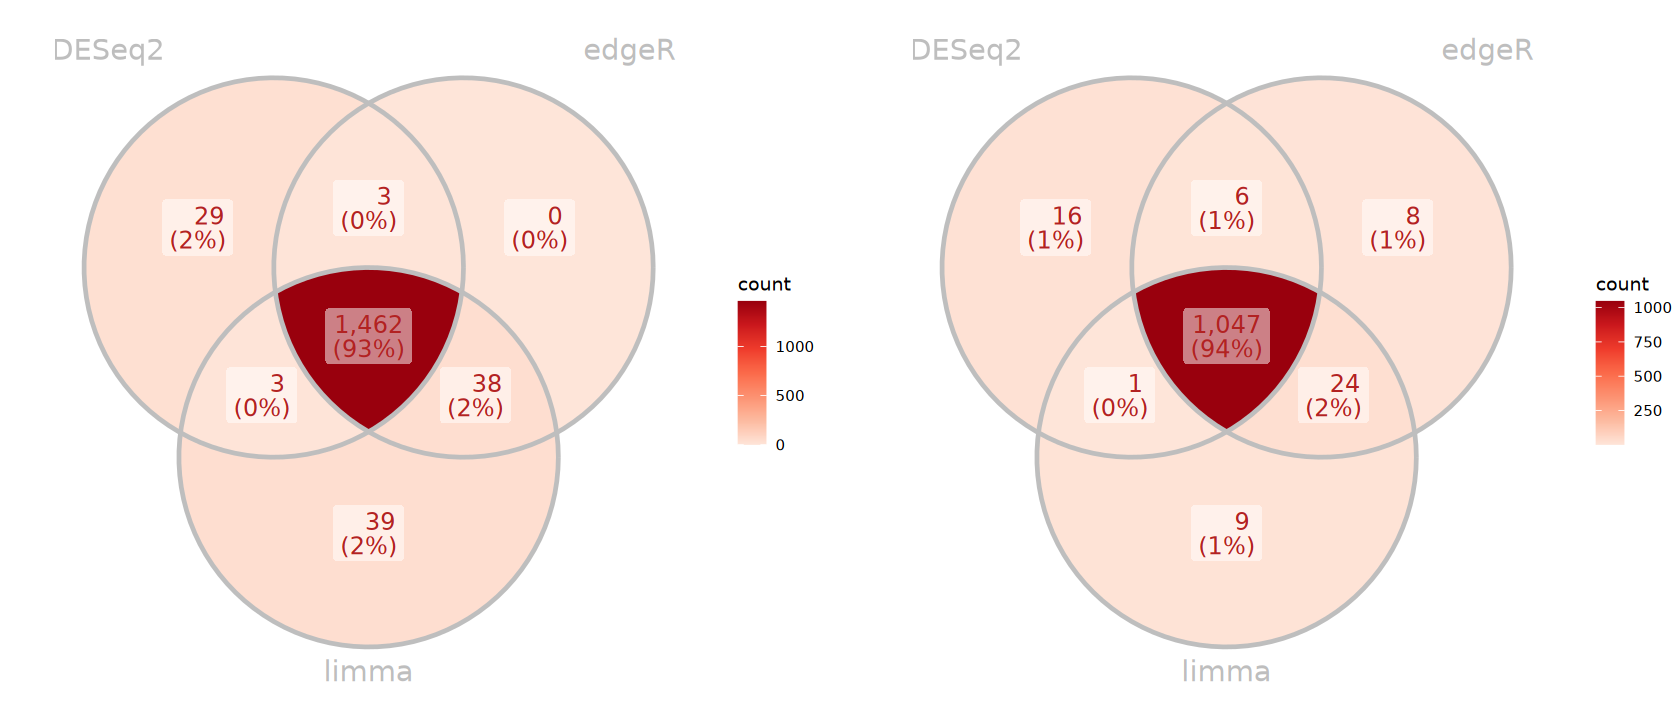

In [121]:
options(repr.plot.width = 14, repr.plot.height = 6)

p1 + plot_spacer() + p2 +
    plot_layout(nrow = 1, widths = c(1, 0.05, 1))

### Upset

In [122]:
suppressPackageStartupMessages(library(UpSetR))

Warning message:
"Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.
ℹ The deprecated feature was likely used in the UpSetR package.
  Please report the issue at <https://github.com/hms-dbmi/UpSetR/issues>."
Warning message:
"The `size` argument of `element_line()` is deprecated as of ggplot2 3.4.0.
ℹ Please use the `linewidth` argument instead.
ℹ The deprecated feature was likely used in the UpSetR package.
  Please report the issue at <https://github.com/hms-dbmi/UpSetR/issues>."


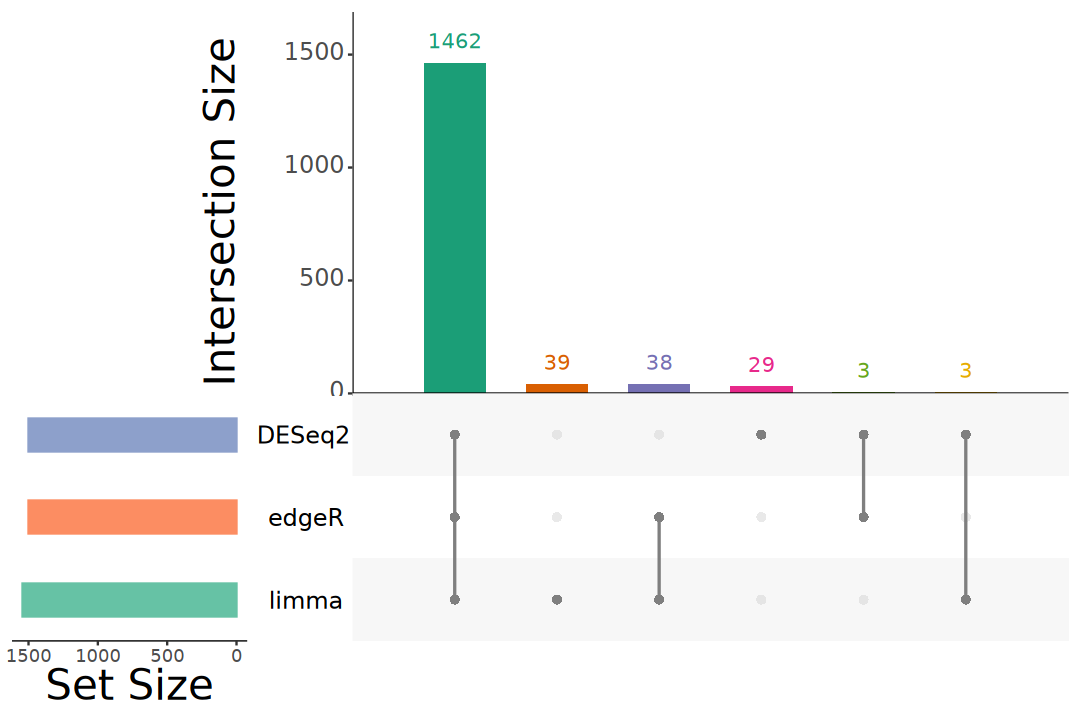

In [123]:
options(repr.plot.width = 9, repr.plot.height = 6)
UpSetR::upset(
    fromList(genes_up), mb.ratio = c(0.55, 0.45),
    order.by = "freq", decreasing = TRUE,
    sets.bar.color = brewer.pal(n = 3, name = "Set2"),
    main.bar.color = brewer.pal(n = 6, name = "Dark2"),
    matrix.color = "grey50",
    text.scale = c(3, 2, 3, 1.5, 2, 2))

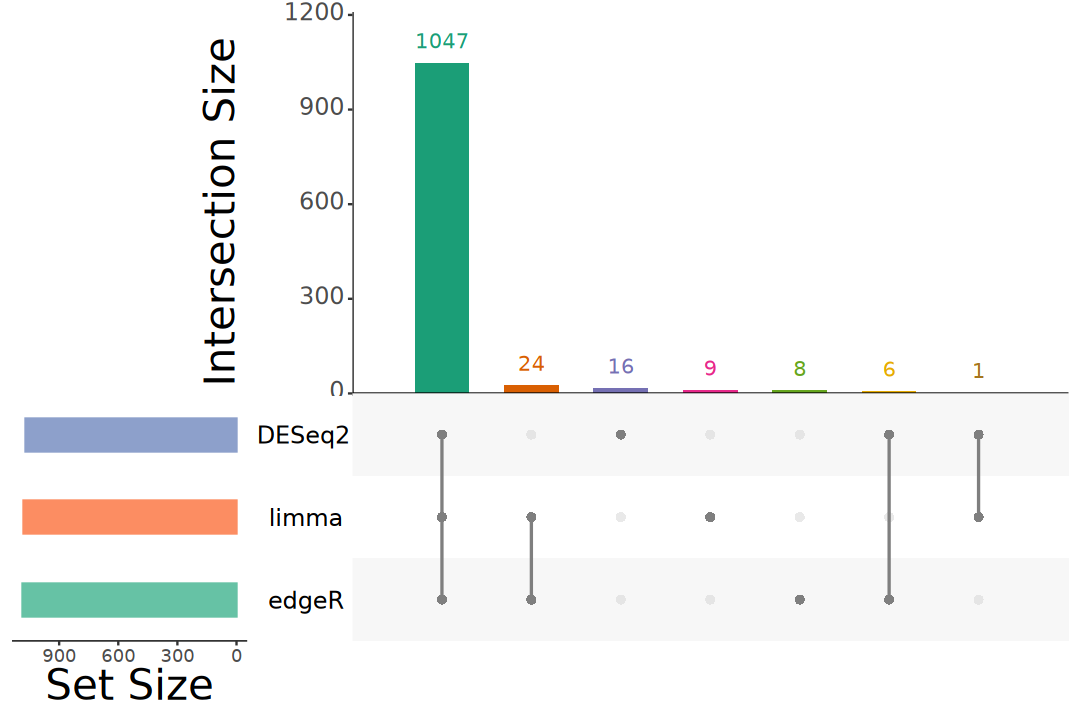

In [124]:
options(repr.plot.width = 9, repr.plot.height = 6)
UpSetR::upset(
    fromList(genes_down), mb.ratio = c(0.55, 0.45),
    order.by = "freq", decreasing = TRUE,
    sets.bar.color = brewer.pal(n = 3, name = "Set2"),
    main.bar.color = brewer.pal(n = 7, name = "Dark2"),
    matrix.color = "grey50",
    text.scale = c(3, 2, 3, 1.5, 2, 2))

## DEGs Visualization

In [125]:
res_lfc <- lfcShrink(dds, coef = "Cell_EpiLC_vs_mESC", type = "apeglm")
summary(res_lfc)

using 'apeglm' for LFC shrinkage. If used in published research, please cite:
    Zhu, A., Ibrahim, J.G., Love, M.I. (2018) Heavy-tailed prior distributions for
    sequence count data: removing the noise and preserving large differences.
    Bioinformatics. https://doi.org/10.1093/bioinformatics/bty895




out of 17154 with nonzero total read count
adjusted p-value < 0.1
LFC > 0 (up)       : 6688, 39%
LFC < 0 (down)     : 6376, 37%
outliers [1]       : 0, 0%
low counts [2]     : 0, 0%
(mean count < 7)
[1] see 'cooksCutoff' argument of ?results
[2] see 'independentFiltering' argument of ?results



In [126]:
degs_result <- res_lfc |> as.data.frame() |> 
    rownames_to_column("gene_id") |>
    dplyr::rename(logFC = log2FoldChange) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS"))) |>
    left_join(
        rowData(dds) |> 
            as.data.frame() |> 
            dplyr::select(symbol, type, basepairs) |>
            rownames_to_column("gene_id"), 
        by = "gene_id") |>
    group_by(result) |>
    arrange(padj, logFC |> abs() |> desc()) |>
    mutate(
        label = ifelse(
            type == "protein_coding" & 
                result %in% c("Up", "Down") & 
                row_number() <= 5, 
            symbol, NA_character_)) |>
    ungroup() |>
    column_to_rownames("gene_id")

table(degs_result$result)
head(degs_result)


   Up  Down    NS 
 1497  1070 14587 

,baseMean,logFC,lfcSE,pvalue,padj,result,symbol,type,basepairs,label
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>,<chr>,<int>,<chr>
ENSMUSG00000074365.13,2042.265,-9.647267,0.2294541,0,0,Down,Crxos,protein_coding,2956,Crxos
ENSMUSG00000053062.16,3667.004,-9.450233,0.1624967,0,0,Down,Jam2,protein_coding,6045,Jam2
ENSMUSG00000030523.18,3062.694,-8.575641,0.1411538,0,0,Down,Trpm1,protein_coding,14746,Trpm1
ENSMUSG00000023903.8,4022.749,8.322598,0.1612292,0,0,Up,Mmp25,protein_coding,5303,Mmp25
ENSMUSG00000031073.6,1148.951,7.986979,0.1924864,0,0,Up,Fgf15,protein_coding,3058,Fgf15
ENSMUSG00000032470.17,1209.286,-7.742034,0.1725026,0,0,Down,Mras,protein_coding,5134,Mras


In [127]:
max_logfc <- degs_result$logFC |> abs() |> 
    max(na.rm = TRUE) |> 
    ceiling()

min_padj <- degs_result$padj |> pmax(1e-300) |>
    (\(x) -log10(x))() |>
    max(na.rm = TRUE) |>
    (\(x) ceiling(x / 5) * 5)()

### MA plot

> - Mean-Difference plot
> - Bland-Altman plot

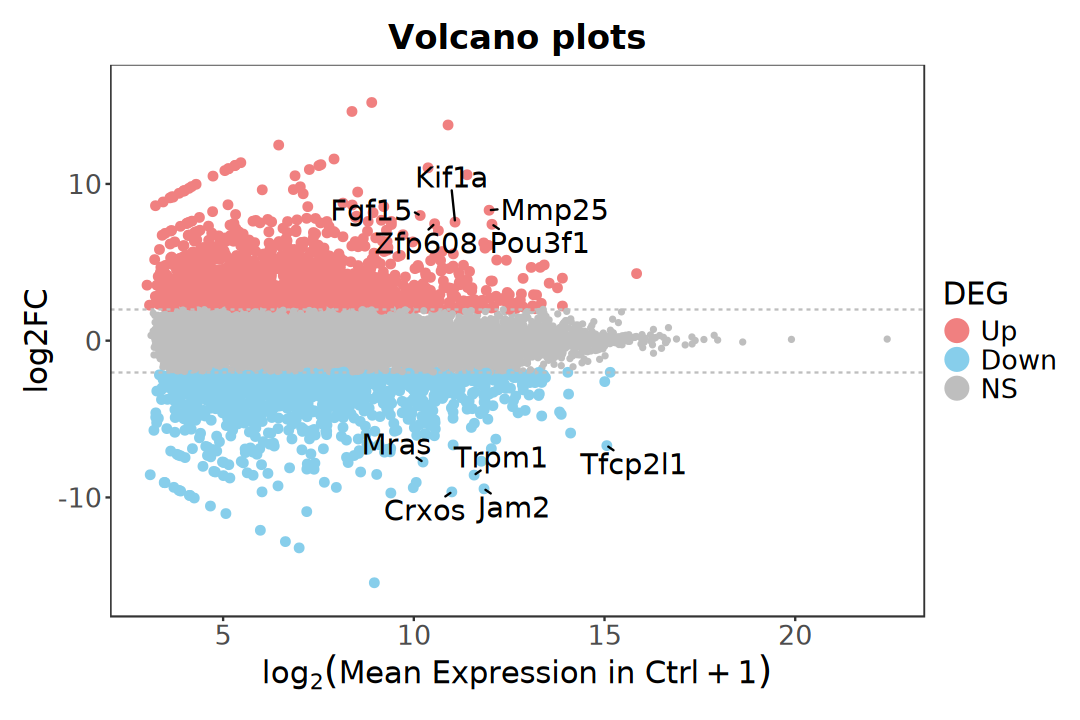

In [128]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(degs_result, aes(x = log2(baseMean + 1), y = logFC)) +
    geom_point(
        aes(color = result, size = result), na.rm = TRUE) +
    geom_hline(
        yintercept = c(-logfc_cutoff, logfc_cutoff),
        linetype = "dashed", color = "gray") +
    geom_text_repel(
        aes(label = label), color = "black", na.rm = TRUE, size = 6, 
        min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf) +
    scale_y_continuous(limits = c(-max_logfc, max_logfc)) +
    scale_color_manual(
        values = c(Up = "LightCoral", Down = "SkyBlue", NS = "gray")) +
    scale_size_manual(
        values = c(Up = 2, Down = 2, NS = 1), guide = "none") +
    guides(
        color = guide_legend(override.aes = list(size = 6))) +
    labs(
        title = "Volcano plots", color = "DEG",
        x = expression(log[2]("Mean Expression in Ctrl" + 1)),
        y = "log2FC") +
    theme_test() + 
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

### Volcano

In [129]:
p1 <- ggplot(degs_result, aes(x = logFC, y = -log10(pmax(padj, 1e-300)))) +
    geom_point(
        aes(color = result, size = result), na.rm = TRUE) +
    geom_hline(
        yintercept = -log10(p_cutoff), 
        linetype = "dashed", color = "gray") + 
    geom_vline(
        xintercept = c(-logfc_cutoff, logfc_cutoff),
        linetype = "dashed", color = "gray") +
    geom_text_repel(
        aes(label = label), color = "black", na.rm = TRUE, size = 6, 
        min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf) +
    scale_x_continuous(
        expand = c(0.1, 0), limits = c(-max_logfc, max_logfc)) +
    scale_y_continuous(
        expand = expansion(mult = c(0, 0.1)), limits = c(0, min_padj)) + 
    scale_color_manual(
        values = c(
            Up = "LightCoral", Down = "SkyBlue", NS = "gray")) +
    scale_size_manual(
        values = c(
            Up = 2, Down = 2, NS = 1), guide = "none") +
    guides(
        color = guide_legend(override.aes = list(size = 6))) +
    labs(
        title = "Volcano plots", color = "DEG",
        x = "log2FC", y = expression(-log[10](P.adjust))) +
    theme_test() + 
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

In [130]:
p2 <- ggplot(degs_result, aes(x = logFC, y = -log10(pmax(padj, 1e-300)))) +
    geom_point(
        aes(color = logFC, size = logFC), na.rm = TRUE) +
    geom_hline(
        yintercept = -log10(p_cutoff), 
        linetype = "dashed", color = "gray") + 
    geom_vline(
        xintercept = c(-logfc_cutoff, logfc_cutoff),
        linetype = "dashed", color = "gray") +
    geom_text_repel(
        aes(label = label), color = "black", na.rm = TRUE, size = 6, 
        min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf) +
    scale_x_continuous(
        expand = c(0.1, 0), limits = c(-max_logfc, max_logfc)) +
    scale_y_continuous(
        expand = expansion(mult = c(0, 0.1)), limits = c(0, min_padj)) + 
    scale_color_gradientn(
        colours = brewer.pal(11, 'RdYlBu') |> rev(), 
        limits = c(-max_logfc, max_logfc)) +
    scale_size_continuous(range = c(1, 3), guide = "none") +
    labs(
        title = "Volcano plots",
        x = "log2FC", y = expression(-log[10](P.adjust))) +
    theme_test() + 
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

In [131]:
p3 <- degs_result |>
    mutate(
        neglog10_padj = -log10(pmax(padj, 1e-300)), 
        neglog10_padj_m = ifelse(
            logFC < 0, -neglog10_padj, neglog10_padj)) |>
    ggplot(aes(x = logFC, y = neglog10_padj)) +
        geom_point(
            aes(color = neglog10_padj_m, size = neglog10_padj), na.rm = TRUE) +
        geom_hline(
            yintercept = -log10(p_cutoff), 
            linetype = "dashed", color = "gray") + 
        geom_vline(
            xintercept = c(-logfc_cutoff, logfc_cutoff),
            linetype = "dashed", color = "gray") +
        geom_text_repel(
            aes(label = label), color = "black", na.rm = TRUE, size = 6, 
            min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf) +
        scale_x_continuous(
            expand = c(0.1, 0), limits = c(-max_logfc, max_logfc)) +
        scale_y_continuous(
            expand = expansion(mult = c(0, 0.1)), limits = c(0, min_padj)) + 
        scale_color_gradientn(
            name = expression(-log[10](P.adjust)),
            colours = brewer.pal(11, 'RdBu') |> rev(), 
            limits = c(-min_padj, min_padj),
            breaks = c(-min_padj, 0, min_padj),
            labels = c(min_padj, 0, min_padj)) +
        scale_size_continuous(range = c(1, 3), guide = "none") +
        labs(
            title = "Volcano plots", color = "DEG",
            x = "log2FC", y = expression(-log[10](P.adjust))) +
        theme_test() + 
        theme(
            plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
            plot.margin = unit(c(1, 1, 1, 1), "line"),
            legend.title = element_text(size = 18), 
            legend.text = element_text(size = 16),
            legend.key.size = unit(1, "cm"),
            axis.title = element_text(size = 18),
            axis.text = element_text(size = 16))

In [132]:
p4 <- ggplot(degs_result, aes(x = logFC, y = -log10(pmax(padj, 1e-300)))) +
    geom_point(
        aes(color = -log10(pmax(padj, 1e-300)), size = -log10(pmax(padj, 1e-300))),
        na.rm = TRUE, alpha = 0.8) +
    geom_hline(
        yintercept = -log10(p_cutoff), 
        linetype = "dashed", color = "gray") + 
    geom_vline(
        xintercept = c(-logfc_cutoff, logfc_cutoff),
        linetype = "dashed", color = "gray") +
    geom_text_repel(
        aes(label = label), color = "black", na.rm = TRUE, size = 6, 
        min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf) +
    scale_x_continuous(
        expand = c(0.1, 0), limits = c(-max_logfc, max_logfc)) +
    scale_y_continuous(
        expand = expansion(mult = c(0, 0.1)), limits = c(0, min_padj)) +  
    # scale_color_viridis_c(
    #     option = "turbo", begin = 0.1, end = 0.9) + 
    # scale_color_gradientn(
    #     colours = brewer.pal(11, 'RdYlBu') |> rev())+
    # scale_color_gradientn(
    #     colors = c("#39489f","#39bbec","#f9ed36","#f38466","#b81f25")) +
    scale_color_gradientn(
        colors = c(
            "#5E4FA2", "#3288BD", "#66C2A5", "#ABDDA4", 
            "#E6F598", "#FFFFBF", "#FEE08B", "#FDAE61", 
            "#F46D43", "#D53E4F", "#9C2007", "#9E0142")) +
    scale_size_continuous(range = c(1, 3), guide = "none") +
    labs(
        title = "Volcano plots", 
        color = expression(-log[10](P.adjust)),
        x = "log2FC", y = expression(-log[10](P.adjust))) +
    theme_test() + 
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        legend.key.size = unit(1, "cm"),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

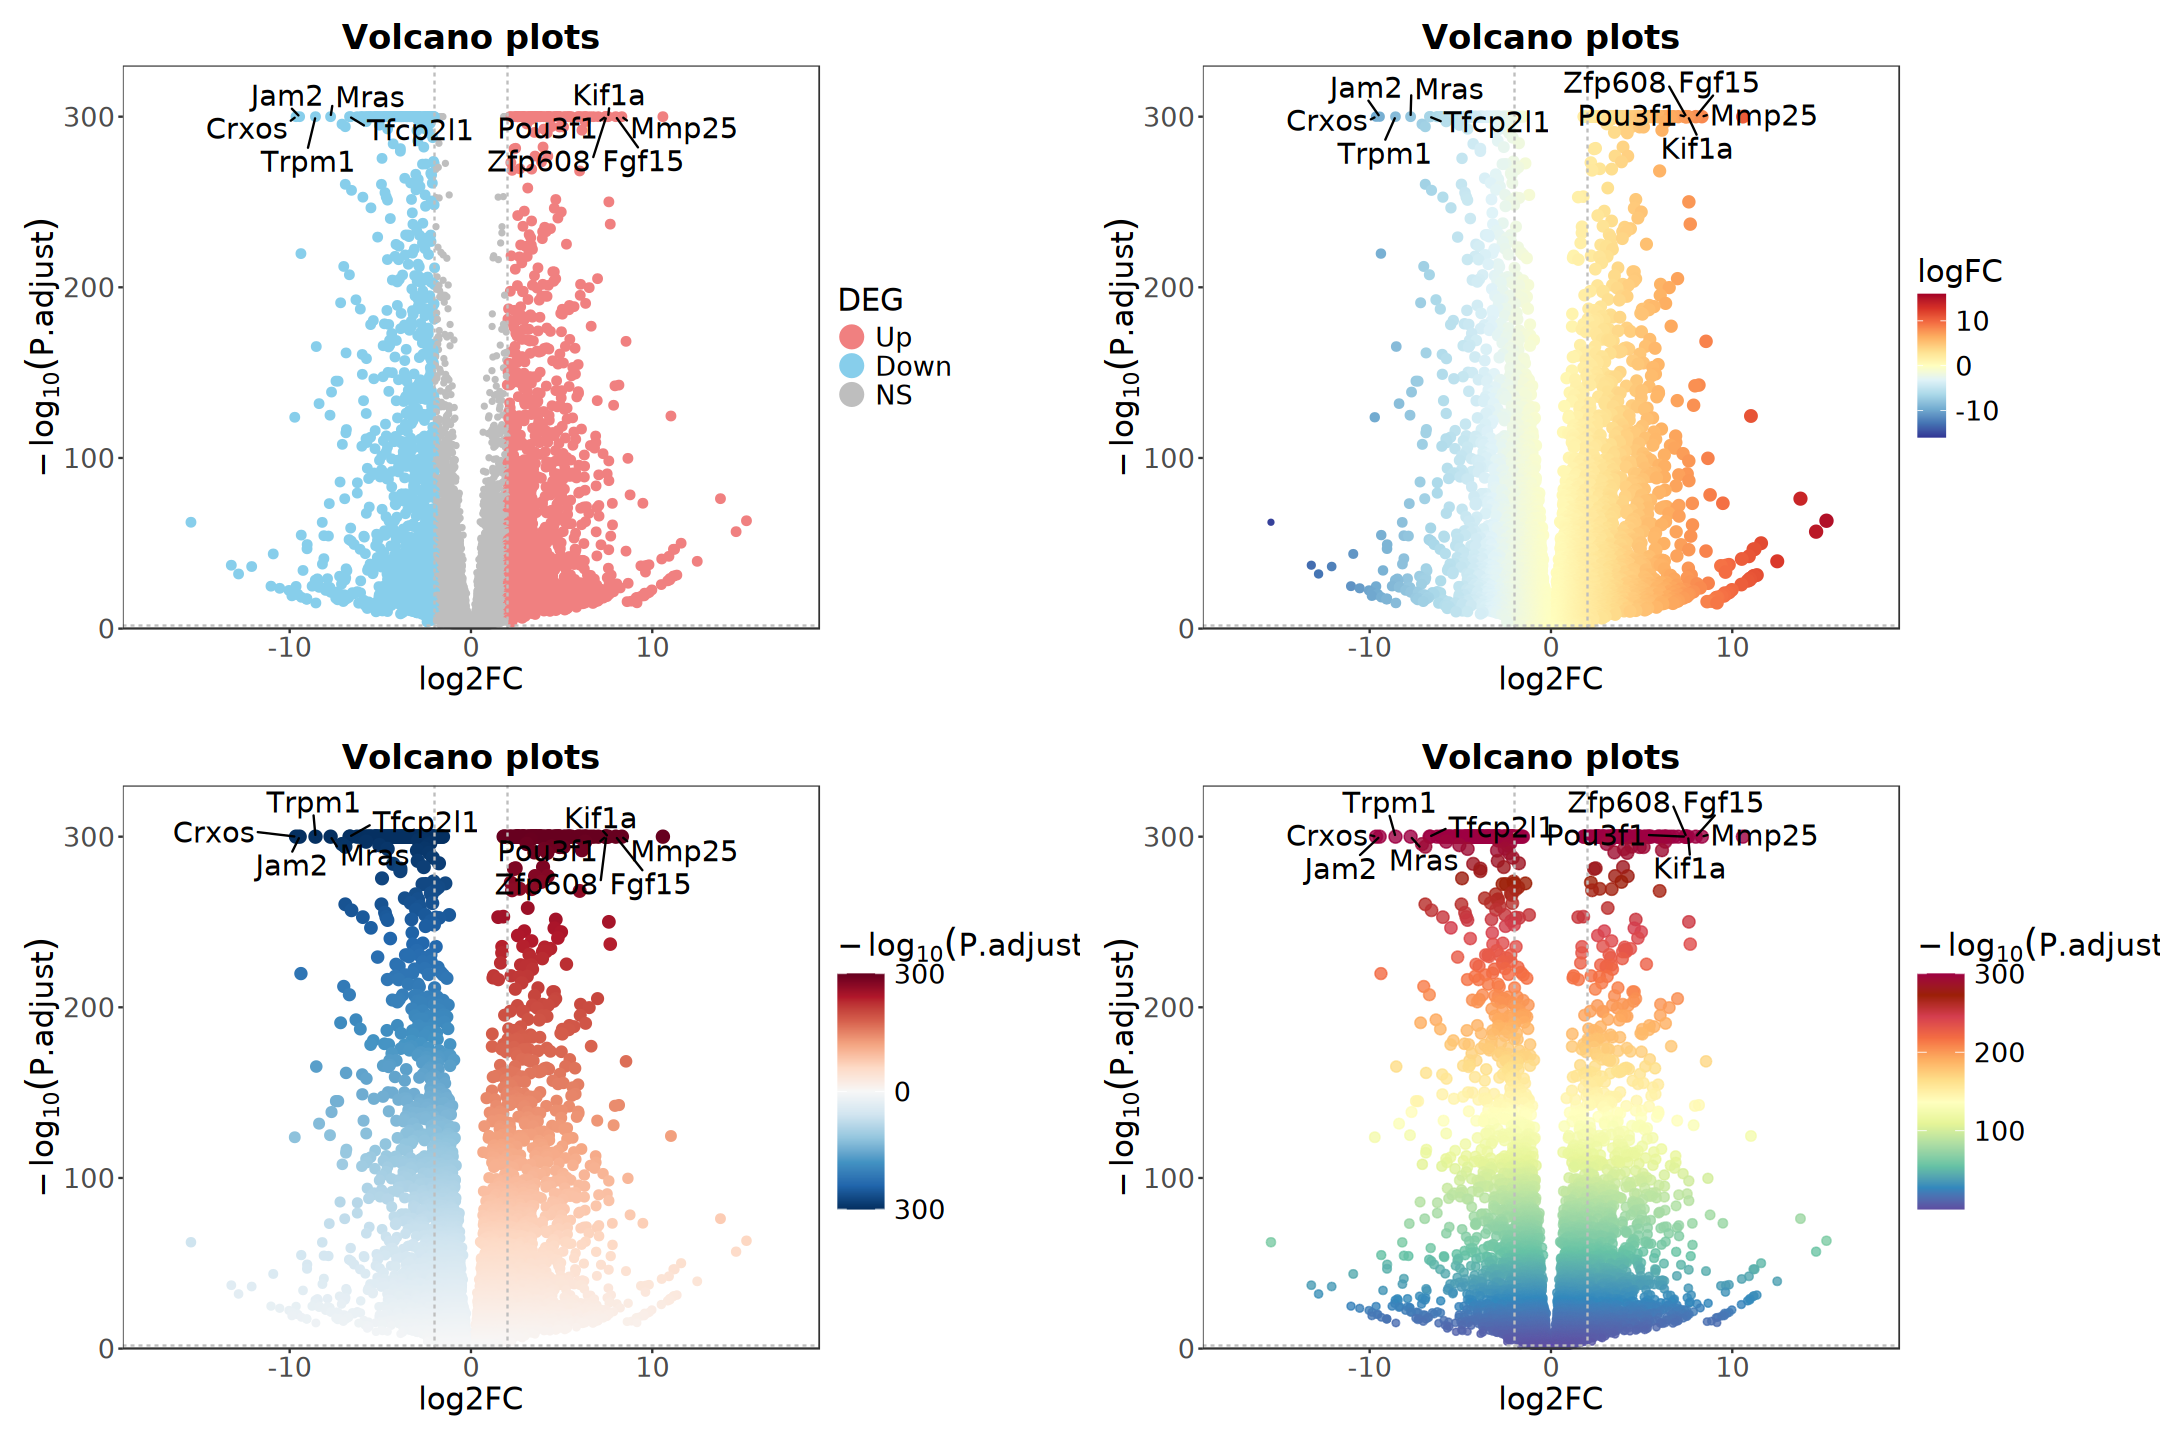

In [133]:
options(repr.plot.width = 18, repr.plot.height = 12)
cowplot::plot_grid(
    p1, p2, p3, p4, nrow = 2, align = "hv", axis = "tblr")

### Scatter Plot

In [134]:
ctrl_samples <- colnames(dds)[dds$Cell == "mESC"]
treat_samples <- colnames(dds)[dds$Cell == "EpiLC"]

mean_expr <- dds |> 
    counts(normalized = TRUE) |> 
    as.data.frame() |> 
    rownames_to_column(var = "gene_id") |> 
    mutate(
        Ctrl_Mean = rowMeans(across(all_of(ctrl_samples))),
        Treat_Mean = rowMeans(across(all_of(treat_samples)))) |> 
    dplyr::select(gene_id, Ctrl_Mean, Treat_Mean)

In [135]:
plot_df <- degs_result |> 
    rownames_to_column(var = "gene_id") |> 
    inner_join(mean_expr, by = "gene_id") |> 
    mutate(
        log2_Ctrl = log2(Ctrl_Mean + 1),
        log2_Treat = log2(Treat_Mean + 1)) |> 
    drop_na(log2_Ctrl, log2_Treat)

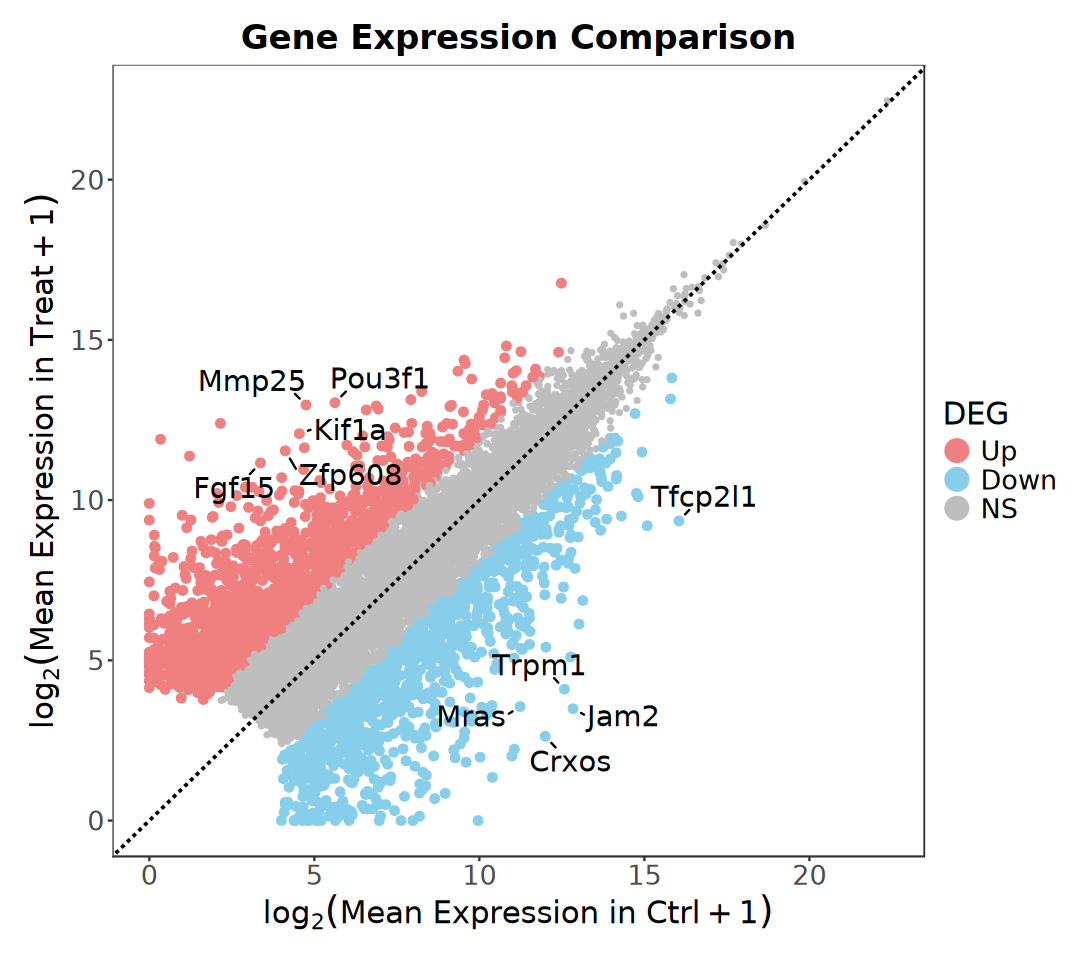

In [136]:
options(repr.plot.width = 9, repr.plot.height = 8)

ggplot(plot_df, aes(x = log2_Ctrl, y = log2_Treat)) +
    geom_point(
        aes(color = result, size = result), na.rm = TRUE) +
    geom_abline(
        intercept = 0, slope = 1, linetype = "dashed", 
        color = "black", linewidth = 0.8) +
    geom_text_repel(
        aes(label = label), color = "black", na.rm = TRUE, size = 6, 
        box.padding = 0.5, point.padding = 0.3,
        min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf) +
    scale_color_manual(
        values = c(Up = "LightCoral", Down = "SkyBlue", NS = "gray")) +
    scale_size_manual(
        values = c(Up = 2, Down = 2, NS = 1), guide = "none") +
    guides(
        color = guide_legend(override.aes = list(size = 6))) +
    labs(
        title = "Volcano plots", color = "DEG",
        x = "log2FC", y = expression(-log[10](P.adjust))) +
    labs(
        title = "Gene Expression Comparison",
        x = expression(log[2]("Mean Expression in Ctrl" + 1)),
        y = expression(log[2]("Mean Expression in Treat" + 1))) + 
    theme_test() + 
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

### Heatmap

In [137]:
heatmap_dat <- degs_result |>
    filter(result %in% c("Up", "Down")) |>
    rownames() |>
    (\(idx) norm_mat[idx, ])()

In [138]:
ar <- degs_result |> 
    dplyr::select(DEG = result, logFC)

ac <- colData(dds) |> as.data.frame() |>
    dplyr::select(Replicate, Cell)

In [139]:
group_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(dds$Cell)),
    levels(dds$Cell))
replicate_colors <- setNames(
    scales::brewer_pal(palette = "Set2")(nlevels(dds$Replicate)),
    levels(dds$Replicate))
deg_colors <- c(Up = "LightCoral", Down = "SkyBlue", NS = "grey")

anno_colors <- list(
    Cell = group_colors, Replicate = replicate_colors, DEG = deg_colors, 
    logFC = colorRampPalette(brewer.pal(9, "PiYG"))(255) |> rev())

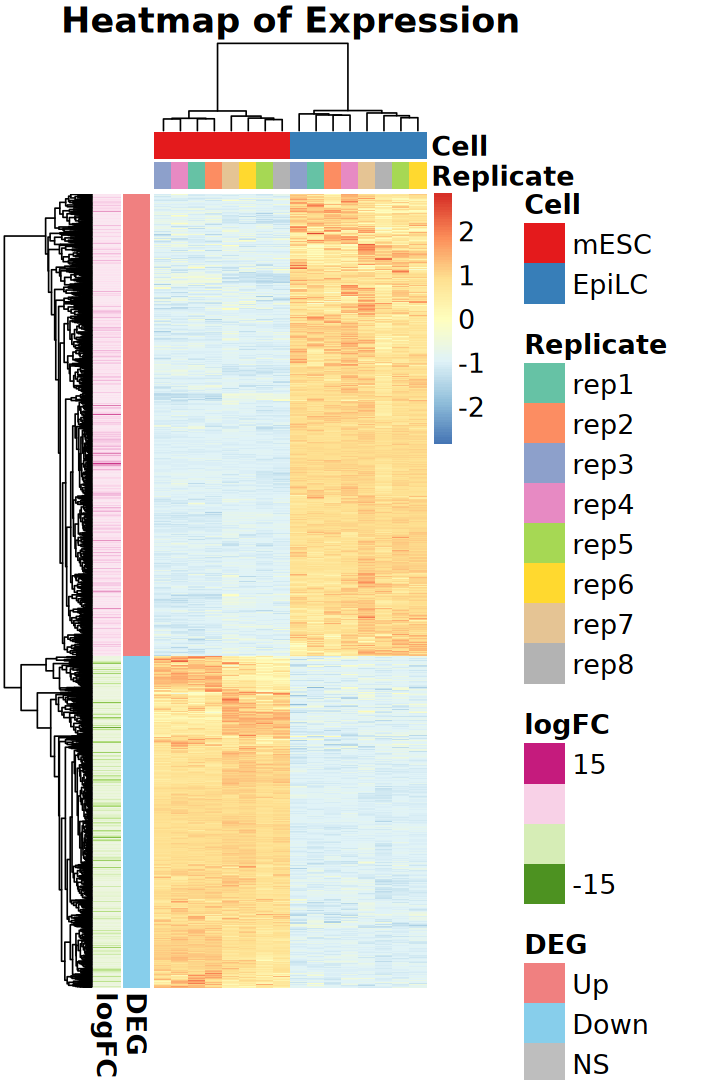

In [140]:
options(repr.plot.width = 6, repr.plot.height = 9)

pheatmap::pheatmap(
    heatmap_dat, scale = "row",
    annotation_row = ar, annotation_col = ac, 
    annotation_colors = anno_colors, 
    main = "Heatmap of Expression", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

### ComplexHeatmap

In [141]:
# suppressPackageStartupMessages(library(circlize))
suppressPackageStartupMessages(library(ComplexHeatmap))

In [142]:
heatmap_dat <- degs_result |>
    filter(result %in% c("Up", "Down")) |>
    rownames() |>
    (\(idx) norm_mat[idx, ])()

In [143]:
heatmap_col <- circlize::colorRamp2(
    breaks = c(-2, 0, 2), 
    colors = brewer.pal(n = 11, name = "RdYlBu")[c(3,6,9)] |> rev())

group_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(dds$Cell)),
    levels(dds$Cell))
replicate_colors <- setNames(
    scales::brewer_pal(palette = "Set2")(nlevels(dds$Replicate)),
    levels(dds$Replicate))

deg_colors <- c(Up = "LightCoral", Down = "SkyBlue", NS = "grey")

In [144]:
ac <- colData(dds) |> as.data.frame() |>
    dplyr::select(Cell, Replicate)

top_anno <- HeatmapAnnotation(
    df = ac, col = list(
        Cell = group_colors, 
        Replicate = replicate_colors))

In [145]:
ar <- degs_result |> 
    dplyr::select(logFC, DEG = result) |>
    rownames_to_column("gene_id") |>
    filter(gene_id %in% rownames(heatmap_dat)) |>
    column_to_rownames("gene_id")

anno_colors <- list(
    DEG = deg_colors, 
    logFC = circlize::colorRamp2(
        breaks = c(-5, 0, 5),
        colors = rev(brewer.pal(n = 3, name = "PiYG"))))

left_anno <- rowAnnotation(
    df = ar, col = anno_colors, show_legend = FALSE)

In [146]:
right_anno <- rowAnnotation(
    foo = anno_mark(
        at = which(!is.na(degs_result$label)),
        labels = degs_result$symbol[which(!is.na(degs_result$label))],
        labels_gp = gpar(fontsize = 12)))

In [147]:
ar <- degs_result |> 
    dplyr::select(DEG = result, logFC)

ac <- colData(dds) |> as.data.frame() |>
    dplyr::select(Replicate, Group)

In [148]:
lg_heatmap <- Legend(
    title = "Expression (z-score)", col_fun = heatmap_col)
lg_group <- Legend(
    title = "Cell", labels = levels(dds$Cell))
lg_replicate <- Legend(
    title = "Replicate", labels = levels(dds$Replicate))
lg_logfc <- Legend(
    title = "logFC", col_fun = anno_colors$logFC)
lg_deg <- Legend(
    labels = levels(degs_result$result), title = "DEG", 
    legend_gp = gpar(fill = deg_colors))

combined_leg <- list(lg_heatmap, lg_group, lg_replicate) |>
    packLegend(direction = "vertical")

In [149]:
ht <- heatmap_dat |> t() |> scale() |> t() |>
    Heatmap(
        name = "Expression", col = heatmap_col,
        top_annotation = top_anno,
        left_annotation = left_anno, 
        right_annotation = right_anno, use_raster = TRUE,
        show_row_names = FALSE, show_column_names = FALSE)

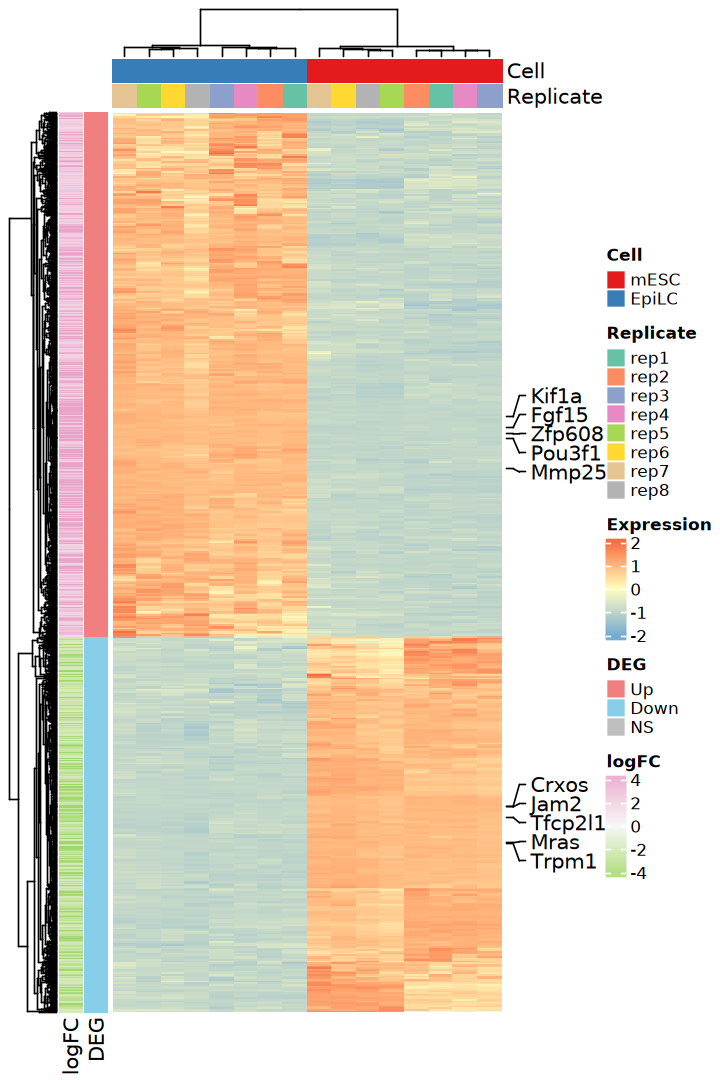

In [150]:
options(repr.plot.width = 6, repr.plot.height = 9)

draw(
    ht + combined_leg, merge_legend = TRUE,
    annotation_legend_list = list(lg_deg, lg_logfc), 
    legend_title_gp = gpar(fontsize = 12, fontface = "bold"),
    legend_labels_gp = gpar(fontsize = 10), 
    padding = unit(c(2, 2, 2, 5), "mm"))

# 6. Gene Function Analysis

## 1). ORA

In [151]:
suppressPackageStartupMessages(library(org.Mm.eg.db))
suppressPackageStartupMessages(library(clusterProfiler))

In [152]:
add_ENTREZID <- function(
    res, orgdb, fromType = "SYMBOL", toType = "ENTREZID", 
    ignoreVersion = FALSE) {
    
    gene_ids <- rownames(res)

    if(fromType == "ENSEMBL" & ignoreVersion) {
        gene_ids <- sub("\\..*$", "", gene_ids)
    }

    gene_map <- clusterProfiler::bitr(
        gene_ids, OrgDb = orgdb, drop = FALSE, 
        fromType = fromType, toType = toType)
    
    idx <- match(gene_ids, gene_map[[fromType]])

    for (col in toType) {
        res[[col]] <- gene_map[[col]][idx]
    }
    
    return(res)
}

In [153]:
deseq2_result <- add_ENTREZID(
    deseq2_result, org.Mm.eg.db, fromType = "ENSEMBL", 
    toType = c("SYMBOL", "ENTREZID"), ignoreVersion = TRUE)
edger_result <- add_ENTREZID(
    edger_result, org.Mm.eg.db, fromType = "ENSEMBL", 
    toType = c("SYMBOL", "ENTREZID"), ignoreVersion = TRUE)
limma_result <- add_ENTREZID(
    limma_result, org.Mm.eg.db, fromType = "ENSEMBL", 
    toType = c("SYMBOL", "ENTREZID"), ignoreVersion = TRUE)

'select()' returned 1:many mapping between keys and columns

Warning message in clusterProfiler::bitr(gene_ids, OrgDb = orgdb, drop = FALSE, :
"11.94% of input gene IDs are fail to map..."
'select()' returned 1:many mapping between keys and columns

Warning message in clusterProfiler::bitr(gene_ids, OrgDb = orgdb, drop = FALSE, :
"11.55% of input gene IDs are fail to map..."
'select()' returned 1:many mapping between keys and columns

Warning message in clusterProfiler::bitr(gene_ids, OrgDb = orgdb, drop = FALSE, :
"11.55% of input gene IDs are fail to map..."


In [154]:
extract_gene_lists <- function(
    results_map, gene_col = "SYMBOL", result_col = "result", 
    directions = c("Up", "Down")) {
        
    lapply(names(results_map), function(method) {
        lapply(directions, function(dir) {
            df <- results_map[[method]]
            df[[gene_col]][df[[result_col]] == dir]
        })
    }) |>
    unlist(recursive = FALSE) |>
    setNames(
        nm = as.vector(t(outer(
            names(results_map), directions, paste, sep = "-"))))
}

In [155]:
results_map <- list(
    DESeq2 = deseq2_result, 
    edgeR  = edger_result,
    limma  = limma_result)

genes_list <- extract_gene_lists(
    results_map, gene_col = "symbol", result_col = "result")

In [156]:
ego_compare <- compareCluster(
    geneCluster = genes_list, fun = enrichGO, 
    universe = unique(c(deseq2_result$SYMBOL, edger_result$SYMBOL)), 
    OrgDb = org.Mm.eg.db, ont = "ALL", 
    keyType = 'SYMBOL', pAdjustMethod = "BH",
    pvalueCutoff = 0.01, qvalueCutoff = 0.05, 
    minGSSize = 10, maxGSSize = 500, readable = TRUE)

In [157]:
ego_compare |> dplyr::select(-one_of("geneID")) |> head()

,Cluster,ONTOLOGY,ID,Description,GeneRatio,BgRatio,RichFactor,FoldEnrichment,zScore,pvalue,p.adjust,qvalue,Count
,<fct>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>
1,DESeq2-Up,BP,GO:0042391,regulation of membrane potential,93/1312,381/13904,0.2440945,2.586806,10.137332,2.788215e-18,1.384349e-14,1.145223e-14,93
2,DESeq2-Up,BP,GO:0098742,cell-cell adhesion via plasma-membrane adhesion molecules,50/1312,169/13904,0.2958580,3.135373,9.015226,8.429565e-14,2.092640e-10,1.731167e-10,50
3,DESeq2-Up,BP,GO:0044057,regulation of system process,93/1312,468/13904,0.1987179,2.105926,7.855750,1.992140e-12,3.296992e-09,2.727485e-09,93
4,DESeq2-Up,BP,GO:0046942,carboxylic acid transport,62/1312,265/13904,0.2339623,2.479429,7.848736,9.830869e-12,1.158957e-08,9.587643e-09,62
5,DESeq2-Up,BP,GO:0015849,organic acid transport,62/1312,266/13904,0.2330827,2.470108,7.814273,1.167127e-11,1.158957e-08,9.587643e-09,62
6,DESeq2-Up,BP,GO:0015711,organic anion transport,72/1312,338/13904,0.2130178,2.257469,7.554460,2.451823e-11,2.028884e-08,1.678424e-08,72


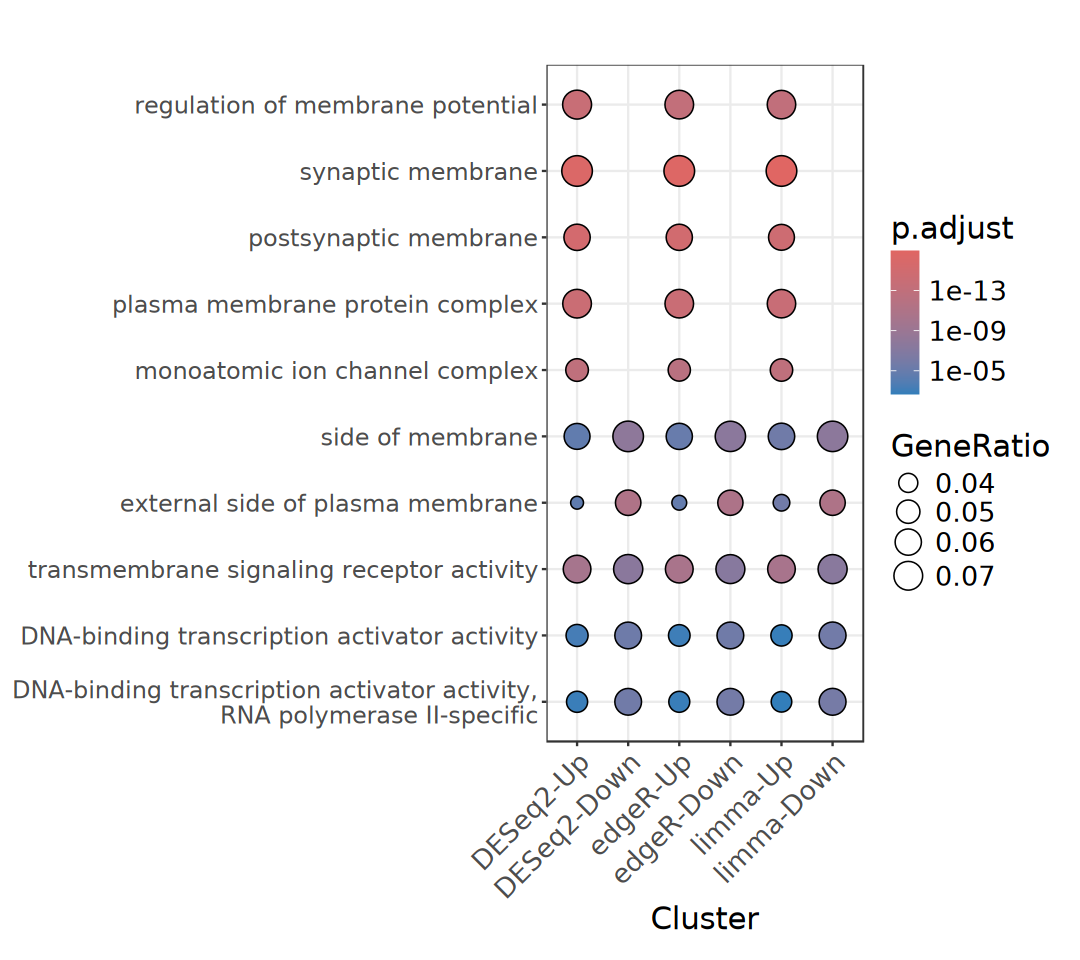

In [158]:
options(repr.plot.width = 9, repr.plot.height = 8)

dotplot(ego_compare, showCategory = 5, label_format = 50) + 
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text.x = element_text(size = 16, angle = 45, hjust = 1), 
        axis.text.y = element_text(size = 14))

In [159]:
genes_list <- extract_gene_lists(
    results_map, gene_col = "ENTREZID", result_col = "result")

In [160]:
ekegg_compare <- compareCluster(
    geneCluster = genes_list, fun = enrichKEGG, 
    universe = unique(c(deseq2_result$ENTREZID, edger_result$ENTREZID)), 
    organism = "mmu", pAdjustMethod = "BH",
    pvalueCutoff = 0.01, qvalueCutoff = 0.05, 
    minGSSize = 10, maxGSSize = 500)

In [161]:
ekegg_compare |> dplyr::select(-one_of("geneID")) |> head()

,Cluster,category,subcategory,ID,Description,GeneRatio,BgRatio,RichFactor,FoldEnrichment,zScore,pvalue,p.adjust,qvalue,Count
,<fct>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>
1,DESeq2-Up,Environmental Information Processing,Signaling molecules and interaction,mmu04514,Cell adhesion molecule (CAM) interaction,36/609,107/6247,0.3364486,3.451222,8.404996,7.383005e-12,2.318263e-09,1.841865e-09,36
2,DESeq2-Up,Environmental Information Processing,Signaling molecules and interaction,mmu04082,Neuroactive ligand signaling,35/609,112/6247,0.3125000,3.205562,7.740485,1.531182e-10,2.403955e-08,1.909947e-08,35
3,DESeq2-Up,Environmental Information Processing,Signaling molecules and interaction,mmu04080,Neuroactive ligand-receptor interaction,39/609,141/6247,0.2765957,2.837264,7.251866,7.826962e-10,8.192221e-08,6.508737e-08,39
4,DESeq2-Up,Organismal Systems,Nervous system,mmu04726,Serotonergic synapse,26/609,82/6247,0.3170732,3.252473,6.747565,2.627951e-08,2.062941e-06,1.639011e-06,26
5,DESeq2-Up,Environmental Information Processing,Signaling molecules and interaction,mmu04512,ECM-receptor interaction,21/609,61/6247,0.3442623,3.531374,6.529250,1.196480e-07,7.513895e-06,5.969806e-06,21
6,DESeq2-Up,Cellular Processes,Cell motility,mmu04820,Cytoskeleton in muscle cells,41/609,182/6247,0.2252747,2.310823,5.898091,1.805034e-07,9.446343e-06,7.505140e-06,41


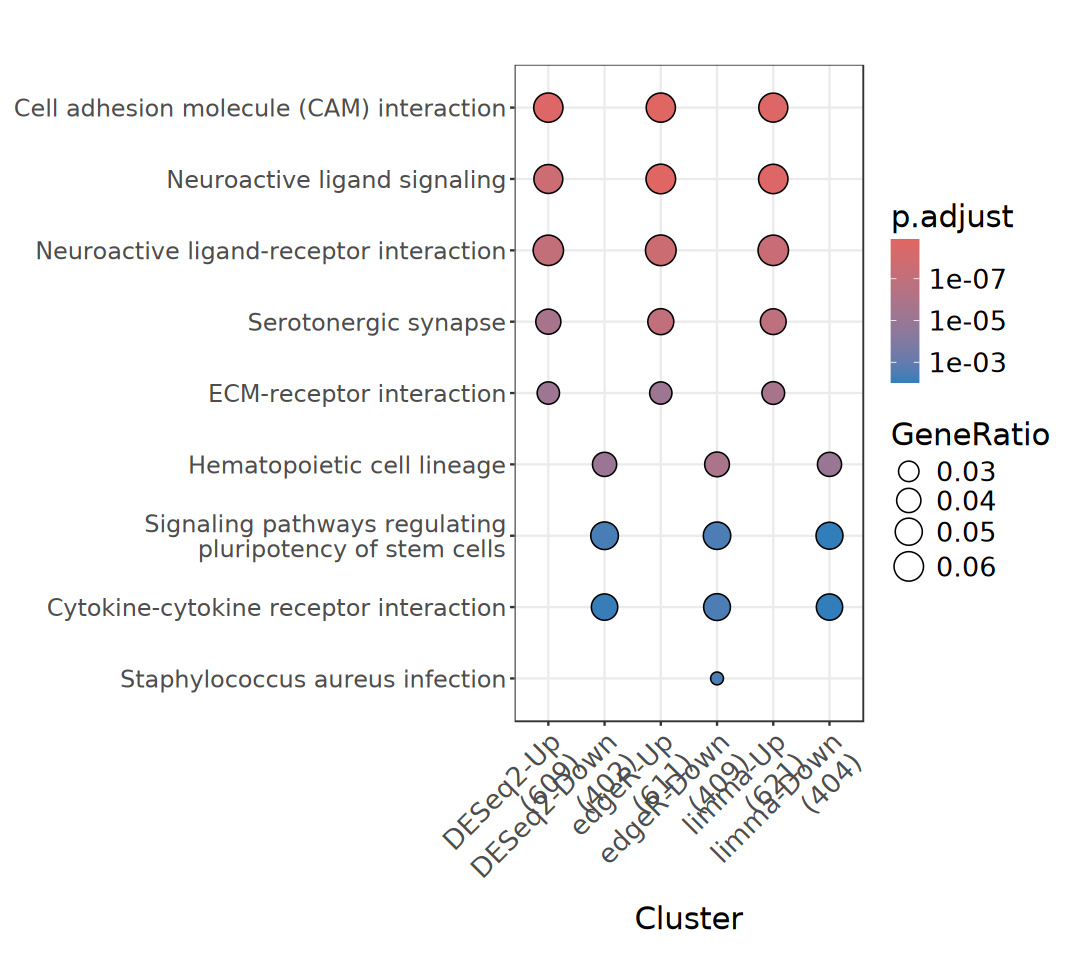

In [162]:
options(repr.plot.width = 9, repr.plot.height = 8)

dotplot(ekegg_compare, showCategory = 5, label_format = 40) + 
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text.x = element_text(size = 16, angle = 45, hjust = 1), 
        axis.text.y = element_text(size = 14))

## 2). GSEA

> Gene Set Enrichment Analysis

# Reference

> 1. Law CW, Alhamdoosh M, Su S, Dong X, Tian L, Smyth GK, Ritchie ME (2018). “RNA-seq analysis is easy as 1-2-3 with limma, Glimma and edgeR.” F1000Research, 5, 1408. https://f1000research.com/articles/5-1408/v3. [RNA-seq analysis is easy as 1-2-3 with limma, Glimma and edgeR](https://www.bioconductor.org/packages/release/workflows/html/RNAseq123.html)
> 2. Law CW, Zeglinski K, Dong X, Alhamdoosh M, Smyth GK, Ritchie ME (2020). “A guide to creating design matrices for gene expression experiments.” F1000Research, 9, 1444. https://f1000research.com/articles/9-1444. [A guide to creating design matrices for gene expression experiments](https://www.bioconductor.org/packages/release/workflows/vignettes/RNAseq123/inst/doc/designmatrices.html)
> 2. Love MI, Anders S, Kim V, Huber W (2016). “RNA-Seq workflow: gene-level exploratory analysis and differential expression.” F1000Research. doi:10.12688/f1000research.7035.2. [RNA-seq workflow: gene-level exploratory analysis and differential expression](https://www.bioconductor.org/packages/release/workflows/html/rnaseqGene.html)
> 3. Chen Y, Lun ATL, Smyth GK (2016). “From reads to genes to pathways: differential expression analysis of RNA-Seq experiments using Rsubread and the edgeR quasi-likelihood pipeline.” F1000Research, 5, 1438. http://f1000research.com/articles/5-1438. [Gene-level RNA-seq differential expression and pathway analysis using Rsubread and the edgeR quasi-likelihood pipeline](https://www.bioconductor.org/packages/release/workflows/html/RnaSeqGeneEdgeRQL.html)